# Peak detection workbench

Edit the detector in cells **A**, **B** and **C**, then **Run All**. Every plot below is redrawn with your edited detector.

## Data used

| Cohort | Recordings | Used in |
|---|---|---|
| Cohort 1, Aim1 (Jun 2025): cagemate / rank | 7 | Sections 2, 3, 6 |
| Cohort 1, Aim1 (Jun 2025): valence (BLRI baseline, RI1 positive, RI2 negative) | 23 (7 + 8 + 8) | Sections 2, 3, 6 |
| Cohort 2, BLA pilot (Jan 2026): cagemate, RI1, RI2 | 118 | Section 6 only |
| Cohort 3, BLA cohort 2 (Jul 2026): cagemate, RI1 | 55 (3 cagemate sessions also in Section 1) | Sections 1, 6 |

Cohorts are numbered by recording date. The Dropbox folder names count BLA cohorts only, so `BLA_ChR_resp_cohort2` is overall **cohort 3**. Section 6 gives the evidence.

- Every plot title says which cohort it shows.
- All signals: raw 20 kHz H5, filtered and downsampled to 400 Hz (0.1-20 Hz band-pass), using the same loaders as the pipelines.
- Subject 5_13 is left out (see `docs/EXCLUSIONS_LOG.md`).

## Sections

1. Old vs new detector on the cohort 3 windows that first showed the undercounting
2. 40 review windows across the Aim1 recordings
3. Whole-recording peak counts vs a snapshot
4. Save a snapshot
5. Check the notebook still matches the pipeline module
6. Which recordings exist, and bad signal per recording, one cell per cohort and session type

## How to judge an edit

- In Section 2, a green ○ is a peak your edit **added** and a red ✕ is a peak it **removed**, compared with the snapshot.
- For each one, ask: did it add a real breath, or remove a false one?
- If the edit helps, save it as a new snapshot in Section 4 and compare later edits to that.

## What cells A-C control

- **A:** which stretches count as dead or bad signal
- **B:** which local maxima count as breaths
- **C:** the full detector (baseline, two passes, cycles)

`workbench_support.py` only loads data, picks windows and draws plots. It never detects peaks.

## Bad signal is left out of plots and summaries

This screen is frozen, so the same data is left out after any edit. It removes:
- dead stretches: 1 s range below 10% of the recording median
- artifacts: 1 s range above 8x the median, or a spike with a full range above 5x
- 10 s on each side of dead stretches and artifacts, where the signal fades in and out
- degraded signal: 5 s running median below 50%

This removes about 10% of the data. Every excluded stretch is listed in `workbench_bad_intervals.csv`.

## Snapshot v1

`v1` is the detector validated on 2026-10-09 (`adaptive_breath_detection.py` v1.0.0). Edits here don't change that module until you copy them over.


## Setup

- Run with the **biopipeline-env** kernel (it has neurokit2).
- This cell moves into the notebook's folder. VS Code starts the kernel in the workspace root, where `workbench_support` can't be imported.


In [36]:
import os
import sys
from pathlib import Path

_cands = [Path(globals().get("__vsc_ipynb_file__", "")).parent, Path.cwd(),
          Path.cwd() / "notebooks/thomas_notebooks/resp_classification/detector_validation"]
NB_DIR = next(p.resolve() for p in _cands if (p / "workbench_support.py").exists())
os.chdir(NB_DIR)
sys.path.insert(0, str(NB_DIR))
print("working in", NB_DIR)


working in C:\Users\thoma\Code\ResearchCode\respiratory_pilot\notebooks\thomas_notebooks\resp_classification\detector_validation


## Cell A: signal validity

Decides which samples are usable. Detection only runs inside the valid segments, and nothing is linked across them.


In [37]:
# ============================================================================
# CELL A: signal validity (what counts as dead or bad signal)
#   validity_mask() decides which samples are usable. Detection only runs inside the
#   valid segments it returns, and nothing is linked across them.
# ============================================================================
import numpy as np
import pandas as pd

VALIDITY_PARAMS = dict(
    block_s=1.0,              # screening block length (s)
    block_hop_s=0.25,         # hop between blocks (s)
    flat_rel_range=0.03,      # block 5-95% range < this x session median range ...
    flat_acf_max=0.5,         # ... and autocorrelation peak (60-500 ms) below this  -> dead / dropout
    low_amp_rel_range=0.15,   # valid but flagged low-amplitude below this
    artifact_rel_range=8.0,   # block range > this x session median                 -> artifact
    artifact_pad_s=0.25,      # padding around artifacts (s)
    min_segment_s=1.0,        # valid runs shorter than this are dropped
)


def running_mean(x, n):
    """Centred running mean; edges average the samples that exist (no zero padding)."""
    x = np.asarray(x, float)
    n = max(int(n), 1)
    s = n // 2
    c = np.concatenate([[0.0], np.cumsum(x)])
    p = np.arange(len(x))
    lo, hi = np.clip(p - s, 0, len(x)), np.clip(p - s + n, 0, len(x))
    return (c[hi] - c[lo]) / (hi - lo)


def _runs(mask):
    m = np.r_[False, np.asarray(mask, bool), False]
    d = np.diff(m.astype(int))
    return list(zip(np.where(d == 1)[0], np.where(d == -1)[0]))


def _acf_peak(seg, fs, lo_s=0.06, hi_s=0.5):
    seg = seg - seg.mean()
    if seg.std() == 0 or len(seg) < int(hi_s * fs) + 2:
        return 0.0
    ac = np.correlate(seg, seg, "full")[len(seg) - 1:]
    return float((ac / ac[0])[int(lo_s * fs):int(hi_s * fs)].max())


def validity_mask(x, fs, P=None):
    """Returns valid (bool per sample), reason (str per sample), low_amp (bool),
    segments [(start, stop)], noise_ptp (sensor-noise peak-to-peak estimate),
    blocks (DataFrame, one row per 1 s block: range, rel = range / median range, acf, decision)."""
    P = P or VALIDITY_PARAMS
    n = len(x)
    reason = np.full(n, "", dtype=object)
    reason[~np.isfinite(x)] = "missing"
    xf = np.where(np.isfinite(x), x, np.nan)
    w, h = max(int(P["block_s"] * fs), 2), max(int(P["block_hop_s"] * fs), 1)
    starts = np.arange(0, max(n - w, 0) + 1, h)
    r = np.full(len(starts), np.nan)
    for k, s in enumerate(starts):
        b = xf[s:s + w]
        b = b[np.isfinite(b)]
        if len(b) > w // 2:
            r[k] = np.subtract(*np.percentile(b, [95, 5]))
    med = np.nanmedian(r)
    low_amp = np.zeros(n, bool)
    flat_blocks, blocks = [], []
    for k, s in enumerate(starts):
        if not np.isfinite(r[k]):
            continue
        rel, sl, acf, dec = r[k] / med, slice(s, s + w), np.nan, "ok"
        if rel > P["artifact_rel_range"]:
            pad = int(P["artifact_pad_s"] * fs)
            a0, a1 = max(0, s - pad), min(n, s + w + pad)
            reason[a0:a1] = np.where(reason[a0:a1] == "", "artifact", reason[a0:a1])
            dec = "artifact"
        elif rel < P["flat_rel_range"]:
            b = xf[sl][np.isfinite(xf[sl])]
            acf = _acf_peak(b, fs)
            if acf < P["flat_acf_max"]:
                reason[sl] = np.where(reason[sl] == "", "flat_or_dropout", reason[sl])
                flat_blocks.append(sl)
                dec = "flat_or_dropout"
            else:
                low_amp[sl] = True
                dec = "low_amp (periodic)"
        elif rel < P["low_amp_rel_range"]:
            low_amp[sl] = True
            dec = "low_amp"
        blocks.append(dict(start_s=s / fs, range=float(r[k]), median_range=float(med), rel=float(rel),
                           acf=acf, decision=dec))
    # noise floor: 250 ms pieces inside dropouts if any, else quietest 1% (capped at 1% of median range)
    q = max(int(0.25 * fs), 2)
    pieces = [np.ptp(xf[sl][i:i + q]) for sl in flat_blocks for i in range(0, w - q + 1, q)
              if np.all(np.isfinite(xf[sl][i:i + q]))]
    if pieces:
        noise_ptp = float(np.median(pieces))
    else:
        m = n // q
        pp = np.ptp(xf[:m * q].reshape(m, q), axis=1)
        noise_ptp = float(min(np.nanpercentile(pp, 1), 0.01 * med))
    segments = []
    for a, b in _runs(reason == ""):
        if b - a >= P["min_segment_s"] * fs:
            segments.append((int(a), int(b)))
        else:
            reason[a:b] = "short_segment"
    valid = reason == ""
    return valid, reason, low_amp & valid, segments, noise_ptp, pd.DataFrame(blocks)


## Cell B: peak selection

Scores every local maximum and keeps the ones that pass the prominence, width and spacing rules. Rejected candidates are kept with a reason.


In [38]:
# ============================================================================
# CELL B: peak selection (which local maxima count as breaths)
#   select_peaks() scores every local maximum of a signal and keeps those that pass the
#   prominence / width / spacing rules. Rejected candidates are returned with a reason.
# ============================================================================
import numpy as np
import pandas as pd
from scipy.signal import find_peaks

PEAK_PARAMS = dict(
    prominence_frac=0.20,      # required prominence = this x local robust range ...
    noise_mult=2.0,            # ... but at least this x noise floor
    local_range_win_s=1.0,     # window for the local range (s)
    local_range_pcts=(10, 90), # local range = p90 - p10
    prominence_wlen_s=1.0,     # prominence bases searched within +/- wlen/2 (None = whole segment)
    min_peak_width_s=0.015,    # half-prominence width; narrower = spike
    min_peak_distance_s=0.06,  # minimum spacing; the taller peak wins
)


def local_range(y, fs, win_s=1.0, pcts=(10, 90)):
    """Per-sample robust range (p_hi - p_lo) in a centred window, computed every 0.1 s."""
    n, w, hop = len(y), max(int(win_s * fs), 3), max(int(0.1 * fs), 1)
    centers = np.arange(0, n, hop)
    vals = [np.subtract(*np.percentile(y[max(0, c - w // 2):min(n, c + w // 2 + 1)], [pcts[1], pcts[0]]))
            for c in centers]
    return np.interp(np.arange(n), centers, vals)


def select_peaks(y, fs, noise_ptp, scale_signal=None, P=None):
    """y: baseline-corrected signal of one valid segment. scale_signal: where the local
    range is measured (default y). Returns (peak indices, candidate rows, local range).
    Candidate rows = every local maximum with prominence >= half the noise floor, each with
    its numbers and reason: 'counted', 'low_prominence', 'spike_width' or 'too_close'."""
    P = P or PEAK_PARAMS
    lr = local_range(y if scale_signal is None else scale_signal, fs, P["local_range_win_s"], P["local_range_pcts"])
    wlen = None if P["prominence_wlen_s"] is None else max(int(P["prominence_wlen_s"] * fs), 3)
    floor = P["noise_mult"] * noise_ptp
    cand, pr = find_peaks(y, prominence=0, wlen=wlen, width=0, rel_height=0.5)
    need = np.maximum(P["prominence_frac"] * lr[cand], floor)
    prom, width = pr["prominences"], pr["widths"] / fs
    ok_prom, ok_width = prom >= need, width >= P["min_peak_width_s"]
    surv = cand[ok_prom & ok_width]
    if len(surv):
        only = np.full(len(y), -np.inf)
        only[surv] = y[surv]
        sel, _ = find_peaks(only, distance=max(int(round(P["min_peak_distance_s"] * fs)), 1))
        sel = np.intersect1d(sel, surv)
    else:
        sel = surv
    keep = set(sel.tolist())
    rows = []
    for c, p, wd, nd, op, ow in zip(cand, prom, width, need, ok_prom, ok_width):
        counted = bool(op and ow and c in keep)
        if p < 0.5 * floor and not counted:
            continue
        why = "counted" if counted else ("low_prominence" if not op else ("spike_width" if not ow else "too_close"))
        rows.append(dict(idx=int(c), prominence=float(p), required=float(nd),
                         req_from_range=float(P["prominence_frac"] * lr[c]), req_from_noise=float(floor),
                         local_range=float(lr[c]), width_s=float(wd), reason=why))
    return np.asarray(sel, int), rows, lr


## Cell C: the detector

Runs on each valid segment: smoothing, a provisional pass to find cycles, a local baseline, the final pass, then a check that every pair of peaks has a real trough between them.


In [39]:
# ============================================================================
# CELL C: the detector (baseline, two passes, cycles)
#   detect_breaths() is what Sections 1-3 run on every recording. It uses cell A for
#   validity and cell B for peak selection.
# ============================================================================
import numpy as np
import pandas as pd
from scipy.signal import butter, filtfilt

DETECTOR_PARAMS = dict(
    smooth_ms=10.0,           # running-mean smoothing (odd window, so no time shift)
    scale_highpass_hz=1.0,    # high-pass used ONLY for pass-A cycles + threshold scale (None = off)
    polarity=1,               # +1: inhalation is positive
)


def _highpass(seg, fs, hz):
    if hz is None:
        return seg
    b, a = butter(2, hz / (fs / 2.0), btype="high")
    return filtfilt(b, a, seg) if len(seg) > 27 else seg - seg.mean()


def _troughs_between(y, pk):
    return np.array([a + int(np.argmin(y[a:b])) for a, b in zip(pk[:-1], pk[1:])], int)


def _cycle_mean_baseline(x, pk):
    """Mean of x over each peak-to-peak cycle, at the cycle centre, interpolated
    (zero net airflow per cycle -> local zero-flow level)."""
    if len(pk) < 2:
        return np.full(len(x), np.nanmean(x))
    c = np.concatenate([[0.0], np.cumsum(x)])
    a, b = pk[:-1], pk[1:]
    return np.interp(np.arange(len(x)), (a + b) / 2.0, (c[b] - c[a]) / (b - a))


def _validate_cycles(y, pk, need_at, rows):
    """The trough between consecutive peaks must be at least the required prominence below
    the LOWER peak; otherwise that peak is dropped (no cycle without evidence)."""
    pk = list(pk)
    changed = True
    while changed and len(pk) > 1:
        changed = False
        for i, t in enumerate(_troughs_between(y, np.asarray(pk))):
            low = pk[i] if y[pk[i]] <= y[pk[i + 1]] else pk[i + 1]
            if y[low] - y[t] < need_at(low) - 1e-9:
                rows[:] = [r for r in rows if r["idx"] != low]          # replace its 'counted' row
                rows.append(dict(idx=int(low), prominence=float(y[low] - y[t]), required=float(need_at(low)),
                                 width_s=np.nan, reason="shallow_trough"))
                pk.remove(low)
                changed = True
                break
    return np.asarray(pk, int)


def detect_breaths(signal, fs, P=None):
    """Returns dict: peaks, troughs (sample indices), smoothed, baseline, valid, reason,
    low_amp, segments, noise_ptp, candidates (every candidate with its numbers and verdict),
    rejected (the non-counted candidates), blocks (Component A's per-block decisions)."""
    P = P or DETECTOR_PARAMS
    x = P["polarity"] * np.asarray(signal, float)
    n = len(x)
    valid, reason, low_amp, segments, noise_ptp, blocks = validity_mask(x, fs)
    sn = max(int(np.floor(fs / 1000.0 * P["smooth_ms"])), 1)
    sn += 1 - sn % 2
    xs, base = np.full(n, np.nan), np.full(n, np.nan)
    peaks, troughs, candidates = [], [], []
    for s0, s1 in segments:
        seg = running_mean(x[s0:s1], sn)
        xs[s0:s1] = seg
        hp = _highpass(seg, fs, P["scale_highpass_hz"])
        pkA, _, _ = select_peaks(hp, fs, noise_ptp)                      # pass A: provisional cycles
        bl = _cycle_mean_baseline(seg, pkA)
        y = seg - bl
        pk, rej, lr = select_peaks(y, fs, noise_ptp, scale_signal=hp)     # pass B: final peaks
        need_at = lambda i: max(PEAK_PARAMS["prominence_frac"] * lr[i], PEAK_PARAMS["noise_mult"] * noise_ptp)  # noqa: E731
        pk = _validate_cycles(y, pk, need_at, rej)
        if len(pk) >= 2:
            bl = _cycle_mean_baseline(seg, pk)                            # refine baseline, same peaks
            y = seg - bl
        base[s0:s1] = bl
        peaks.append(pk + s0)
        troughs.append(_troughs_between(y, pk) + s0 if len(pk) > 1 else np.array([], int))
        candidates += [dict(r, idx=r["idx"] + s0) for r in rej]
    cat = lambda v: np.concatenate(v).astype(int) if v else np.array([], int)  # noqa: E731
    cols = ["idx", "prominence", "required", "req_from_range", "req_from_noise", "local_range", "width_s", "reason"]
    cand = pd.DataFrame(candidates, columns=cols).sort_values("idx").reset_index(drop=True)
    return dict(peaks=cat(peaks), troughs=cat(troughs), smoothed=xs, baseline=base, valid=valid,
                reason=reason, low_amp=low_amp, segments=segments, noise_ptp=noise_ptp, blocks=blocks,
                candidates=cand, rejected=cand[cand.reason != "counted"].reset_index(drop=True),
                params=dict(PEAK_PARAMS))


## Section 1: Old vs new detector on cohort 3

**Cohort:** Cohort 3, BLA cohort 2 (Jul 2026; Dropbox `2026/BLA_ChR_resp_cohort2`): cagemate. Sessions 11_3, 10_3 and 11_2.

### Where these windows come from

- Sequoia's QC notebook for cohort 3. Local copy: [START_HERE_load_and_inspect_features 1.ipynb](../../seq-sent/START_HERE_load_and_inspect_features%201.ipynb). On Sequoia's machine: `C:\Users\sjs93\OneDrive\Documents\GitHub\respiratory_pilot\outputs\aim1_summer2026_ranked_recs\START_HERE_load_and_inspect_features.ipynb`
- Sequoia's Teams screenshot showed the old code counting **4** peaks at 300-301.5 s and **15** at 550-551.5 s.
- Sequoia's own fix (`max(15 ADC, 12% of local 1 s span)`, 40 ms spacing) is the "prominence fix" figure in that notebook. It isn't run here, but NEW matches its counts in every window.
- Our audit figures for the Aim1 cagemate recordings are in [`seq-sent/detector_audit/results/figures/`](../../seq-sent/detector_audit/results/figures/).

### How to read each pair

- **Top, OLD:** your legacy BreathMetrics peak-finder, re-run here on the same signal.
- **Bottom, NEW:** the detector in cells A-C.
- Same time axis and same signal (`load_rank_resp_signal_interactions`, 20 kHz to 400 Hz).

### The two rules

- **OLD:** a peak counts if `height > cutoff`, with `cutoff = mean + std/2` of the **whole session**. It also has to survive BreathMetrics' consensus and peak/trough alternation steps.
- **NEW:** a peak counts if `prominence >= max(0.20 x local 1 s range, 2 x noise floor)`, its half-width is at least 15 ms, and it is at least 60 ms from a taller peak.
- The table under each pair shows these numbers for every candidate. `[range]` or `[noise]` says which term set the requirement.


In [40]:
%matplotlib inline
import workbench_support as wb          # loading / plotting / tables only, no detection
import pandas as pd
pd.set_option("display.max_columns", 20)


### 1.1 Session 11_3, 300-301.5 s: breaths too small for the old cutoff
- **OLD: 0 peaks** (Sequoia's run: 4). Cutoff = `0.1 + 1428/2 = 714`. Transients up to ±35,000 inflate the std. The tallest breath here is 101.
- **NEW: 14 of 15 candidates count.** Each needs about 18 (20% of the local range). The rejected one (301.17 s, prominence 11) is a shoulder, not a cycle.

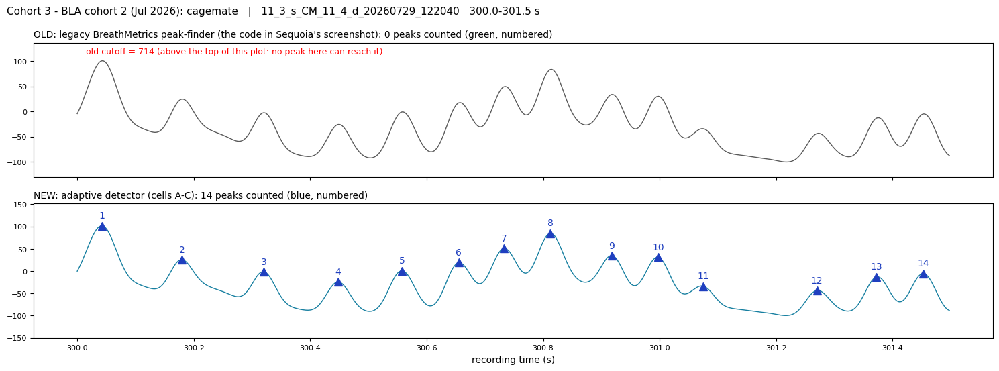

OLD rule  count if height > cutoff,  cutoff = mean + std/2 = 0.1 + 1428.2/2 = 714.3   (mean/std over the WHOLE 626 s session)
NEW rule  count if prominence >= max(0.20 x local range, 2 x noise floor 3.4 = 6.9),  half-width >= 15 ms,  >= 60 ms from a taller peak


,t (s),OLD height,OLD: height > cutoff?,OLD result,NEW prominence,"NEW required = max(frac x range, mult x noise)",NEW: prom >= required?,width (ms),NEW result
0,300.043,100.7,101 > 714? no,NOT counted: below cutoff,118.9,"max(0.20 x 87, 6.9) = 17.5 [range]",119 >= 17? yes,53.9,counted
1,300.180,24.7,25 > 714? no,NOT counted: below cutoff,61.2,"max(0.20 x 85, 6.9) = 17.1 [range]",61 >= 17? yes,43.8,counted
2,300.320,-2.5,-3 > 714? no,NOT counted: below cutoff,77.7,"max(0.20 x 100, 6.9) = 19.9 [range]",78 >= 20? yes,47.2,counted
3,300.447,-26.1,-26 > 714? no,NOT counted: below cutoff,62.0,"max(0.20 x 105, 6.9) = 20.9 [range]",62 >= 21? yes,43.4,counted
4,300.558,-1.0,-1 > 714? no,NOT counted: below cutoff,86.2,"max(0.20 x 96, 6.9) = 19.3 [range]",86 >= 19? yes,47.8,counted
5,300.655,17.2,17 > 714? no,NOT counted: below cutoff,64.2,"max(0.20 x 93, 6.9) = 18.5 [range]",64 >= 19? yes,38.6,counted
6,300.733,49.2,49 > 714? no,NOT counted: below cutoff,69.5,"max(0.20 x 93, 6.9) = 18.6 [range]",70 >= 19? yes,40.1,counted
7,300.812,83.3,83 > 714? no,NOT counted: below cutoff,99.2,"max(0.20 x 94, 6.9) = 18.7 [range]",99 >= 19? yes,45.8,counted
8,300.918,33.8,34 > 714? no,NOT counted: below cutoff,61.9,"max(0.20 x 91, 6.9) = 18.3 [range]",62 >= 18? yes,38.6,counted
9,300.998,30.3,30 > 714? no,NOT counted: below cutoff,78.4,"max(0.20 x 90, 6.9) = 18.0 [range]",78 >= 18? yes,43.1,counted


In [41]:
wb.plot_old_vs_new(detect_breaths, 0)

### 1.2 Session 11_3, 550-551.5 s: same failure, bigger breaths
- **OLD: 0 peaks** (Sequoia's run: 15). Breaths are 45-261 high and the cutoff is still 714.
- **NEW: all 17 count.** Each clears its requirement (39-49) by 2.5-6x, so the count doesn't depend on the exact 20% setting.

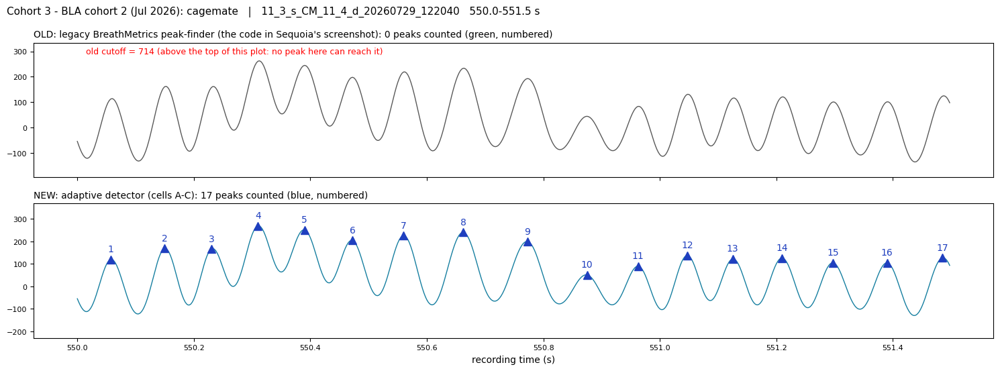

OLD rule  count if height > cutoff,  cutoff = mean + std/2 = 0.1 + 1428.2/2 = 714.3   (mean/std over the WHOLE 626 s session)
NEW rule  count if prominence >= max(0.20 x local range, 2 x noise floor 3.4 = 6.9),  half-width >= 15 ms,  >= 60 ms from a taller peak


,t (s),OLD height,OLD: height > cutoff?,OLD result,NEW prominence,"NEW required = max(frac x range, mult x noise)",NEW: prom >= required?,width (ms),NEW result
0,550.058,112.8,113 > 714? no,NOT counted: below cutoff,223.3,"max(0.20 x 195, 6.9) = 39.1 [range]",223 >= 39? yes,40.9,counted
1,550.150,161.0,161 > 714? no,NOT counted: below cutoff,270.7,"max(0.20 x 217, 6.9) = 43.5 [range]",271 >= 43? yes,42.1,counted
2,550.230,157.5,157 > 714? no,NOT counted: below cutoff,197.1,"max(0.20 x 234, 6.9) = 46.8 [range]",197 >= 47? yes,36.8,counted
3,550.310,261.0,261 > 714? no,NOT counted: below cutoff,260.0,"max(0.20 x 244, 6.9) = 48.8 [range]",260 >= 49? yes,43.9,counted
4,550.390,244.8,245 > 714? no,NOT counted: below cutoff,209.7,"max(0.20 x 244, 6.9) = 48.8 [range]",210 >= 49? yes,41.0,counted
5,550.472,198.0,198 > 714? no,NOT counted: below cutoff,204.5,"max(0.20 x 244, 6.9) = 48.8 [range]",205 >= 49? yes,39.8,counted
6,550.560,218.7,219 > 714? no,NOT counted: below cutoff,272.8,"max(0.20 x 244, 6.9) = 48.8 [range]",273 >= 49? yes,44.5,counted
7,550.663,233.5,234 > 714? no,NOT counted: below cutoff,305.1,"max(0.20 x 238, 6.9) = 47.6 [range]",305 >= 48? yes,51.0,counted
8,550.773,192.9,193 > 714? no,NOT counted: below cutoff,259.6,"max(0.20 x 234, 6.9) = 46.9 [range]",260 >= 47? yes,51.7,counted
9,550.875,44.6,45 > 714? no,NOT counted: below cutoff,118.2,"max(0.20 x 223, 6.9) = 44.6 [range]",118 >= 45? yes,42.2,counted


In [42]:
wb.plot_old_vs_new(detect_breaths, 1)

### 1.3 Session 11_3, 442-443.5 s: small breaths on a drift
- **OLD: 0 peaks.** The breaths ride a downward drift (heights -115 to 135).
- **NEW: 13 count.** Two close calls:
  - the bump at 442.19 s misses by 0.8 (22.6 vs 23.4);
  - at 443.3-443.5 s the local range drops to about 30, so the noise floor (6.9) sets the requirement.

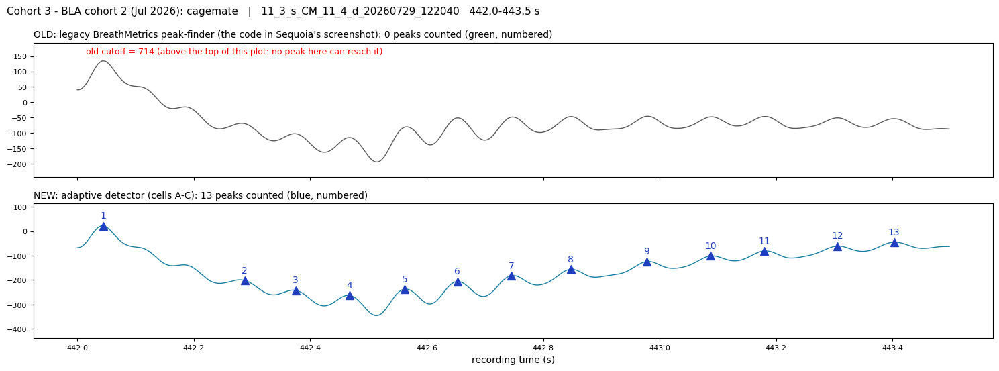

OLD rule  count if height > cutoff,  cutoff = mean + std/2 = 0.1 + 1428.2/2 = 714.3   (mean/std over the WHOLE 626 s session)
NEW rule  count if prominence >= max(0.20 x local range, 2 x noise floor 3.4 = 6.9),  half-width >= 15 ms,  >= 60 ms from a taller peak
(1 tiny wiggles with prominence < 30% of the requirement not listed)


,t (s),OLD height,OLD: height > cutoff?,OLD result,NEW prominence,"NEW required = max(frac x range, mult x noise)",NEW: prom >= required?,width (ms),NEW result
0,442.045,134.6,135 > 714? no,NOT counted: below cutoff,110.7,"max(0.20 x 140, 6.9) = 28.0 [range]",111 >= 28? yes,105.0,counted
1,442.190,-16.3,-16 > 714? no,NOT counted: below cutoff,22.6,"max(0.20 x 117, 6.9) = 23.4 [range]",23 >= 23? no,33.5,NOT counted: prominence too small
2,442.288,-69.6,-70 > 714? no,NOT counted: below cutoff,27.4,"max(0.20 x 104, 6.9) = 20.7 [range]",27 >= 21? yes,39.9,counted
3,442.375,-102.4,-102 > 714? no,NOT counted: below cutoff,42.9,"max(0.20 x 90, 6.9) = 18.0 [range]",43 >= 18? yes,46.1,counted
4,442.467,-114.6,-115 > 714? no,NOT counted: below cutoff,63.0,"max(0.20 x 78, 6.9) = 15.5 [range]",63 >= 16? yes,46.8,counted
5,442.562,-80.9,-81 > 714? no,NOT counted: below cutoff,78.8,"max(0.20 x 68, 6.9) = 13.7 [range]",79 >= 14? yes,45.8,counted
6,442.652,-51.0,-51 > 714? no,NOT counted: below cutoff,75.1,"max(0.20 x 65, 6.9) = 13.1 [range]",75 >= 13? yes,45.9,counted
7,442.745,-48.6,-49 > 714? no,NOT counted: below cutoff,55.7,"max(0.20 x 65, 6.9) = 13.0 [range]",56 >= 13? yes,43.5,counted
8,442.848,-46.6,-47 > 714? no,NOT counted: below cutoff,44.1,"max(0.20 x 65, 6.9) = 12.9 [range]",44 >= 13? yes,43.7,counted
9,442.978,-45.8,-46 > 714? no,NOT counted: below cutoff,41.5,"max(0.20 x 49, 6.9) = 9.9 [range]",41 >= 10? yes,46.7,counted


In [ ]:
wb.plot_old_vs_new(detect_breaths, 2)

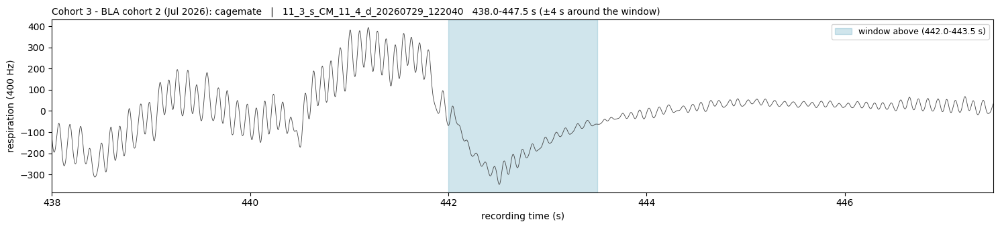

In [48]:
# Context for 1.3: the full respiration trace from 4 s before to 4 s after the window above
import matplotlib.pyplot as plt
import numpy as np

PAD_S = 4.0
key, t0, t1, _ = wb.ORIGINAL_PANELS[2]
sig = wb._cohort3_signal(key)
fs = wb.FS
c0, c1 = max(0, int((t0 - PAD_S) * fs)), min(len(sig), int((t1 + PAD_S) * fs))
tt = np.arange(c0, c1) / fs

fig, ax = plt.subplots(figsize=(15, 3.5))
ax.plot(tt, sig[c0:c1], color="0.25", lw=0.6)
ax.axvspan(t0, t1, color="#167fa0", alpha=0.2, label=f"window above ({t0:.1f}-{t1:.1f} s)")
ax.set_xlim(tt[0], tt[-1])
ax.set_xlabel("recording time (s)")
ax.set_ylabel("respiration (400 Hz)")
ax.legend(loc="upper right", fontsize=9)
ax.set_title(f"{wb.cohort_label(key)}   |   {key}   {tt[0]:.1f}-{tt[-1]:.1f} s (±{PAD_S:.0f} s around the window)",
             loc="left", fontsize=10)
fig.tight_layout()
plt.show()

### 1.4 Session 10_3, 50-51.5 s: control, both methods agree
- **Both count 13.**
- No large transients, so the OLD cutoff is `0.1 + 422/2 = 211` and every breath (606-975) clears it.
- The NEW requirement here is 216-311, about 12x higher than in 11_3, because it scales with local breath size.

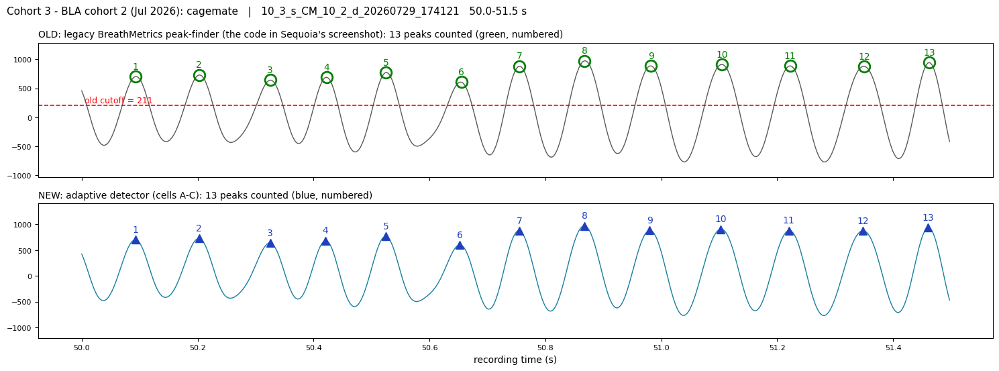

OLD rule  count if height > cutoff,  cutoff = mean + std/2 = 0.1 + 421.9/2 = 211.1   (mean/std over the WHOLE 640 s session)
NEW rule  count if prominence >= max(0.20 x local range, 2 x noise floor 12.3 = 24.7),  half-width >= 15 ms,  >= 60 ms from a taller peak


,t (s),OLD height,OLD: height > cutoff?,OLD result,NEW prominence,"NEW required = max(frac x range, mult x noise)",NEW: prom >= required?,width (ms),NEW result
0,50.093,702.7,703 > 211? yes,counted,1136.9,"max(0.20 x 1082, 24.7) = 216.5 [range]",1137 >= 216? yes,50.9,counted
1,50.203,730.3,730 > 211? yes,counted,1190.6,"max(0.20 x 1081, 24.7) = 216.2 [range]",1191 >= 216? yes,53.0,counted
2,50.325,641.3,641 > 211? yes,counted,1060.2,"max(0.20 x 1111, 24.7) = 222.2 [range]",1060 >= 222? yes,52.6,counted
3,50.420,683.9,684 > 211? yes,counted,1151.4,"max(0.20 x 1142, 24.7) = 228.5 [range]",1151 >= 228? yes,46.0,counted
4,50.525,773.1,773 > 211? yes,counted,1382.5,"max(0.20 x 1208, 24.7) = 241.7 [range]",1382 >= 242? yes,51.6,counted
5,50.653,606.1,606 > 211? yes,counted,1080.6,"max(0.20 x 1300, 24.7) = 260.1 [range]",1081 >= 260? yes,52.1,counted
6,50.755,881.6,882 > 211? yes,counted,1492.7,"max(0.20 x 1370, 24.7) = 273.9 [range]",1493 >= 274? yes,51.5,counted
7,50.867,974.5,975 > 211? yes,counted,1634.3,"max(0.20 x 1419, 24.7) = 283.9 [range]",1634 >= 284? yes,58.0,counted
8,50.980,885.1,885 > 211? yes,counted,1545.1,"max(0.20 x 1453, 24.7) = 290.5 [range]",1545 >= 291? yes,57.0,counted
9,51.102,908.6,909 > 211? yes,counted,1646.1,"max(0.20 x 1507, 24.7) = 301.3 [range]",1646 >= 301? yes,63.5,counted


In [ ]:
wb.plot_old_vs_new(detect_breaths, 3)

### 1.5 Session 11_2, 490-491.5 s: signal loss
- **Both count 0.**
- OLD: nothing reaches 206.
- NEW: cell A marks the stretch invalid. The 1 s ranges are 5-9 against a session median of 1,116 (`rel ≈ 0.006 < 0.03`, ACF < 0.5).
- **Possible flaw:** two blocks just before this window (ACF 0.55-0.60) pass as "low_amp (periodic)" at 0.7% of normal amplitude. Over Sequoia's masked 482-516 s, this lets NEW count **65 peaks** (see 1.7).

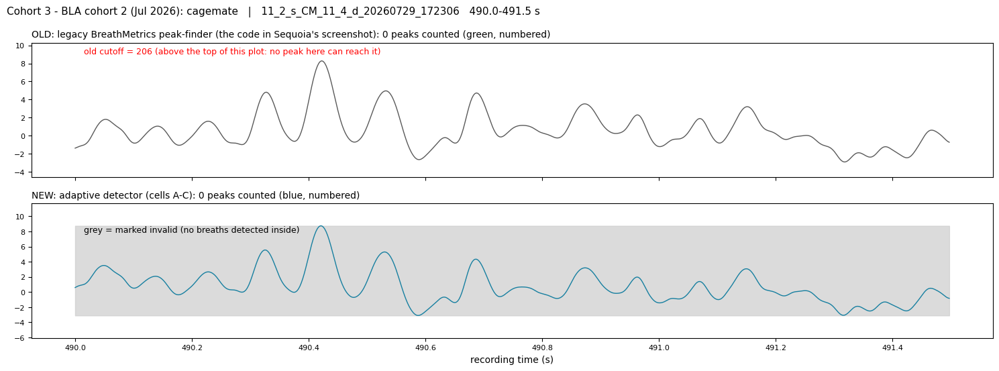

OLD rule  count if height > cutoff,  cutoff = mean + std/2 = 0.1 + 411.6/2 = 205.9   (mean/std over the WHOLE 716 s session)
NEW rule  count if prominence >= max(0.20 x local range, 2 x noise floor 5.7 = 11.4),  half-width >= 15 ms,  >= 60 ms from a taller peak
Component A blocks in this window: rel = range / median range = 0.004-0.008; ACF 0.18-0.60; decisions: flat_or_dropout x7, low_amp (periodic) x2
NEW: no candidates - Component A marked this stretch invalid, so no peaks are searched:


,block_start_s,range,median_range,rel,acf,decision
0,489.25,7.9,1116.0,7.9 / 1116.0 = 0.007,0.60,low_amp (periodic)
1,489.50,9.0,1116.0,9.0 / 1116.0 = 0.008,0.55,low_amp (periodic)
2,489.75,8.7,1116.0,8.7 / 1116.0 = 0.008,0.33,flat_or_dropout
3,490.00,6.7,1116.0,6.7 / 1116.0 = 0.006,0.34,flat_or_dropout
4,490.25,6.7,1116.0,6.7 / 1116.0 = 0.006,0.33,flat_or_dropout
5,490.50,6.2,1116.0,6.2 / 1116.0 = 0.006,0.18,flat_or_dropout
6,490.75,4.9,1116.0,4.9 / 1116.0 = 0.004,0.35,flat_or_dropout
7,491.00,5.4,1116.0,5.4 / 1116.0 = 0.005,0.27,flat_or_dropout
8,491.25,5.2,1116.0,5.2 / 1116.0 = 0.005,0.24,flat_or_dropout


In [ ]:
wb.plot_old_vs_new(detect_breaths, 4)

### 1.6 Session 11_2, 521-522.5 s: control after the dropout
- **Both count 15.**
- Breaths are 588-951 high (above 206). Prominences are 1,058-1,541, far above the requirement (228-264).

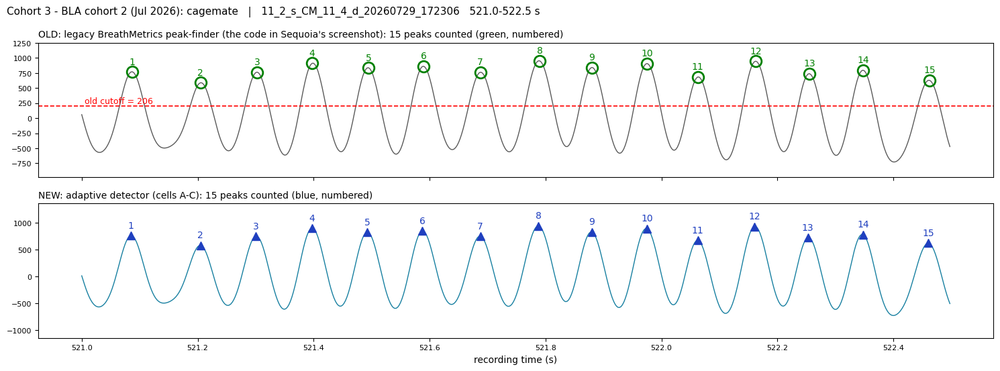

OLD rule  count if height > cutoff,  cutoff = mean + std/2 = 0.1 + 411.6/2 = 205.9   (mean/std over the WHOLE 716 s session)
NEW rule  count if prominence >= max(0.20 x local range, 2 x noise floor 5.7 = 11.4),  half-width >= 15 ms,  >= 60 ms from a taller peak


,t (s),OLD height,OLD: height > cutoff?,OLD result,NEW prominence,"NEW required = max(frac x range, mult x noise)",NEW: prom >= required?,width (ms),NEW result
0,521.085,767.1,767 > 206? yes,counted,1321.6,"max(0.20 x 1140, 11.4) = 228.0 [range]",1322 >= 228? yes,48.3,counted
1,521.205,588.2,588 > 206? yes,counted,1058.3,"max(0.20 x 1179, 11.4) = 235.8 [range]",1058 >= 236? yes,45.0,counted
2,521.300,755.6,756 > 206? yes,counted,1258.1,"max(0.20 x 1230, 11.4) = 246.0 [range]",1258 >= 246? yes,44.5,counted
3,521.398,910.9,911 > 206? yes,counted,1481.4,"max(0.20 x 1231, 11.4) = 246.2 [range]",1481 >= 246? yes,46.0,counted
4,521.492,834.8,835 > 206? yes,counted,1396.9,"max(0.20 x 1271, 11.4) = 254.1 [range]",1397 >= 254? yes,45.4,counted
5,521.587,857.1,857 > 206? yes,counted,1416.9,"max(0.20 x 1260, 11.4) = 252.0 [range]",1417 >= 252? yes,45.7,counted
6,521.688,762.6,763 > 206? yes,counted,1270.5,"max(0.20 x 1301, 11.4) = 260.2 [range]",1270 >= 260? yes,45.6,counted
7,521.788,951.0,951 > 206? yes,counted,1468.4,"max(0.20 x 1319, 11.4) = 263.8 [range]",1468 >= 264? yes,48.5,counted
8,521.880,841.8,842 > 206? yes,counted,1339.0,"max(0.20 x 1316, 11.4) = 263.2 [range]",1339 >= 263? yes,44.3,counted
9,521.975,906.7,907 > 206? yes,counted,1476.8,"max(0.20 x 1310, 11.4) = 262.0 [range]",1477 >= 262? yes,46.5,counted


In [ ]:
wb.plot_old_vs_new(detect_breaths, 5)

### 1.7 Session 11_2, 499.8-501.3 s: where NEW can go wrong
Extra window, not in Sequoia's notebook.
- Blocks here are 2.6-4.8% of normal amplitude, but their ACF (0.59-0.79) passes cell A as periodic low-amplitude breathing.
- `0.20 x range` (5-8) is below the noise floor, so every requirement is the noise floor (11.4). **15 ripples count.**
- They may be noise, or real breathing through a slipping sensor.
- **To test a fix in cell A:** mark blocks below `flat_rel_range` as dead regardless of ACF, or raise `flat_rel_range` or `flat_acf_max`.

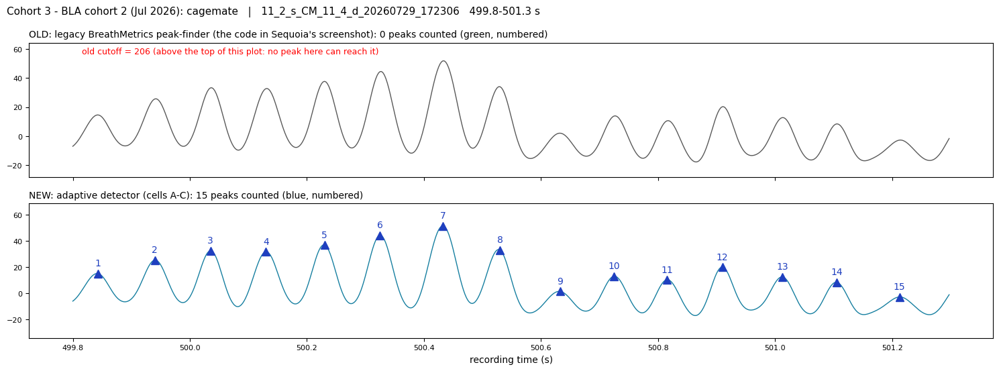

OLD rule  count if height > cutoff,  cutoff = mean + std/2 = 0.1 + 411.6/2 = 205.9   (mean/std over the WHOLE 716 s session)
NEW rule  count if prominence >= max(0.20 x local range, 2 x noise floor 5.7 = 11.4),  half-width >= 15 ms,  >= 60 ms from a taller peak
Component A blocks in this window: rel = range / median range = 0.026-0.048; ACF 0.59-0.79; decisions: low_amp x6, low_amp (periodic) x3


,t (s),OLD height,OLD: height > cutoff?,OLD result,NEW prominence,"NEW required = max(frac x range, mult x noise)",NEW: prom >= required?,width (ms),NEW result
0,499.842,14.6,15 > 206? no,NOT counted: below cutoff,21.7,"max(0.20 x 37, 11.4) = 11.4 [noise]",22 >= 11? yes,44.8,counted
1,499.940,25.6,26 > 206? no,NOT counted: below cutoff,31.1,"max(0.20 x 41, 11.4) = 11.4 [noise]",31 >= 11? yes,43.5,counted
2,500.035,33.2,33 > 206? no,NOT counted: below cutoff,39.7,"max(0.20 x 41, 11.4) = 11.4 [noise]",40 >= 11? yes,41.7,counted
3,500.130,32.7,33 > 206? no,NOT counted: below cutoff,41.0,"max(0.20 x 41, 11.4) = 11.4 [noise]",41 >= 11? yes,45.4,counted
4,500.230,37.7,38 > 206? no,NOT counted: below cutoff,44.4,"max(0.20 x 40, 11.4) = 11.4 [noise]",44 >= 11? yes,42.7,counted
5,500.325,44.4,44 > 206? no,NOT counted: below cutoff,51.4,"max(0.20 x 40, 11.4) = 11.4 [noise]",51 >= 11? yes,43.9,counted
6,500.433,51.8,52 > 206? no,NOT counted: below cutoff,59.6,"max(0.20 x 40, 11.4) = 11.4 [noise]",60 >= 11? yes,48.7,counted
7,500.530,34.0,34 > 206? no,NOT counted: below cutoff,40.2,"max(0.20 x 40, 11.4) = 11.4 [noise]",40 >= 11? yes,41.2,counted
8,500.632,2.0,2 > 206? no,NOT counted: below cutoff,13.3,"max(0.20 x 39, 11.4) = 11.4 [noise]",13 >= 11? yes,41.5,counted
9,500.725,13.8,14 > 206? no,NOT counted: below cutoff,31.5,"max(0.20 x 36, 11.4) = 11.4 [noise]",31 >= 11? yes,48.7,counted


In [ ]:
wb.plot_old_vs_new(detect_breaths, 6)

## Section 2: 40 review windows across the Aim1 recordings

**Cohorts:** Aim1 cagemate first, then Aim1 valence (BLRI, RI1, RI2). Each panel title starts with its cohort in brackets.

- 4 s windows, spread evenly across the 30 recordings and across time in each one.
- Bad signal is left out.
- Every panel shows NEW only.

### Markers

| marker | meaning | counted as a breath? |
|---|---|---|
| blue line | signal (lightly smoothed) | |
| grey dashed line | local baseline (the detector's zero-flow estimate) | |
| blue ▲ | peak | **yes** |
| purple ▼ | trough between two counted peaks | |
| orange ● | **near-miss:** rejected, but its prominence reached at least 50% of the requirement. Check these first for missed breaths | **no** |
| green ○ | counted now, **not** in the snapshot (your edit **added** it) | yes |
| red ✕ | in the snapshot, **not** counted now (your edit **removed** it) | no |
| grey shading | cell A marked it invalid | |

### What to look for

- **Missed breath:** a clear cycle with no ▲, often with an orange ● on it.
- **Extra breath:** a ▲ on something that isn't a full rise and fall.
- Each title gives the peak count and the changes against the snapshot.


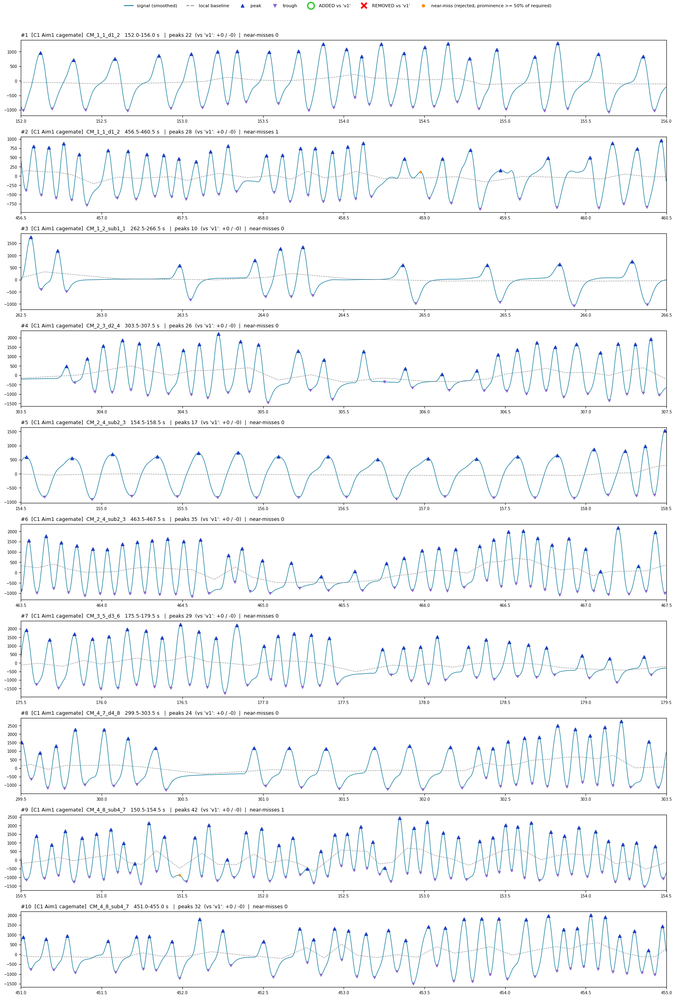

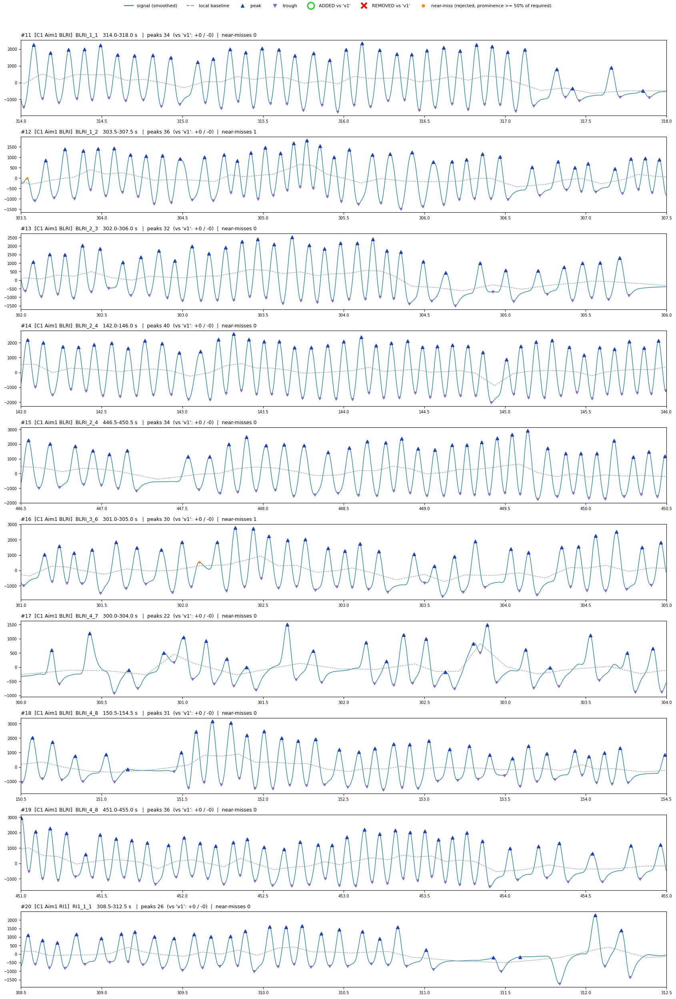

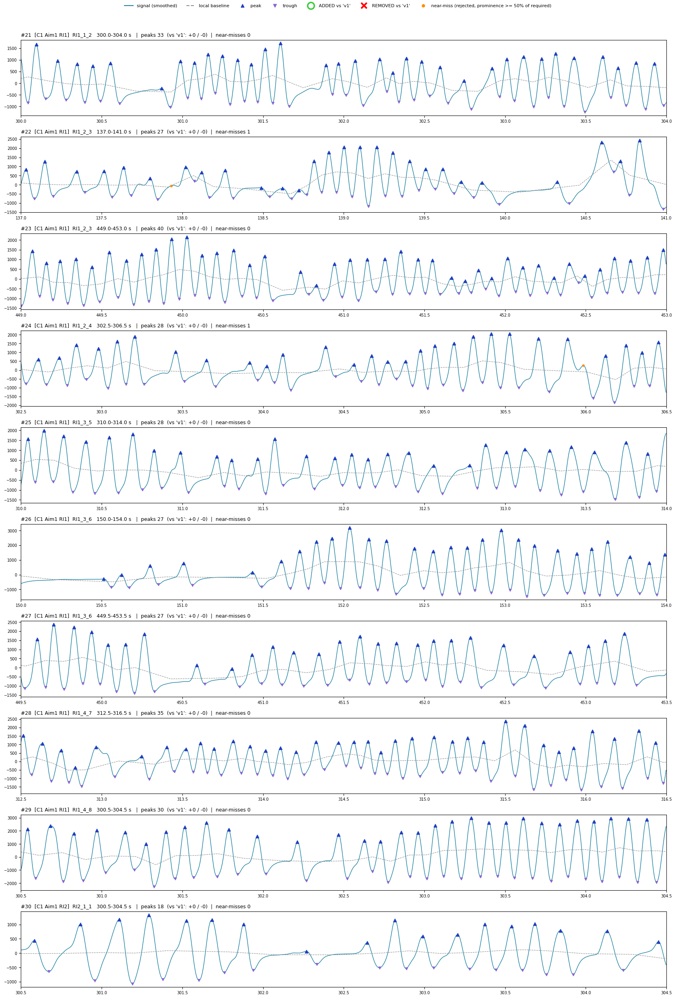

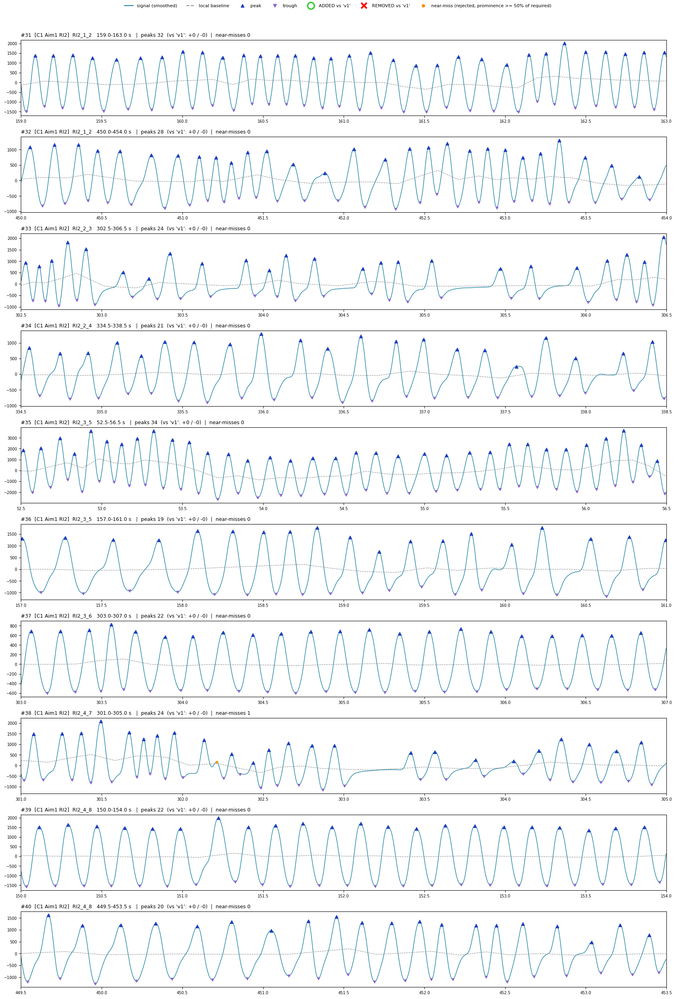

In [ ]:
# ============================================================================
# SECTION 2: run your detector on every Aim1 recording and plot the same 40 windows
#   green O = peak ADDED vs the snapshot, red X = peak REMOVED vs the snapshot,
#   orange dot = near-miss (rejected, but prominence >= 50% of what was required),
#   grey shading = samples your validity_mask() marked invalid.
# ============================================================================
%matplotlib inline
import workbench_support as wb          # loading / window choice / plotting only

COMPARE_TO = "v1"        # snapshot to compare against (see Section 4); None = no comparison
SHOW_LEGACY = False      # True: also draw the legacy BreathMetrics peaks (grey circles)

recs = wb.recordings()                   # cached 400 Hz signals, same loaders as the pipelines
bad = wb.bad_intervals(recs)            # frozen bad-signal screen -> workbench_bad_intervals.csv
windows = wb.select_windows(recs)        # frozen, evenly spread, good-signal windows
results = wb.run_all(detect_breaths, recs)
if COMPARE_TO and wb.load_snapshot(COMPARE_TO) is None:
    wb.save_snapshot(results, COMPARE_TO, params=dict(VALIDITY_PARAMS=VALIDITY_PARAMS, PEAK_PARAMS=PEAK_PARAMS,
                                                      DETECTOR_PARAMS=DETECTOR_PARAMS))
panel_table = wb.plot_windows(results, windows, compare_to=COMPARE_TO, show_legacy=SHOW_LEGACY)


## Section 3: Whole-recording peak counts vs the snapshot

**Cohorts:** all Aim1 recordings (cagemate and valence). The `cohort` column says which.

- Counts every peak in good signal, not just the 40 windows.
- `added` / `removed` compare against the snapshot set in Section 2.


In [ ]:
import pandas as pd
pd.set_option("display.max_rows", 60)
print("Panels with changes:", panel_table.query("added > 0 or removed > 0").panel.tolist())
print(f"Excluded as bad signal: {bad.dur_s.sum() / 60:.1f} min in {bad.key.nunique()} recordings "
      f"(details: workbench_bad_intervals.csv)")
wb.summary(results, compare_to=COMPARE_TO)


Panels with changes: []
Excluded as bad signal: 31.2 min in 22 recordings (details: workbench_bad_intervals.csv)


,key,cohort,analysed_min,excluded_pct,peaks,rate_hz,detector_invalid_pct,snapshot_peaks,added,removed,change_pct
0,CM_1_1_d1_2,C1 Aim1 cagemate,8.154,20.138,3369,6.886,0.0,3369,0,0,0.0
1,CM_1_2_sub1_1,C1 Aim1 cagemate,7.669,24.023,2458,5.342,0.0,2458,0,0,0.0
2,CM_2_3_d2_4,C1 Aim1 cagemate,9.332,8.423,4087,7.299,0.0,4087,0,0,0.0
3,CM_2_4_sub2_3,C1 Aim1 cagemate,10.366,0.000,3898,6.267,0.0,3898,0,0,0.0
4,CM_3_5_d3_6,C1 Aim1 cagemate,5.923,0.000,2857,8.039,0.0,2857,0,0,0.0
5,CM_4_7_d4_8,C1 Aim1 cagemate,10.053,0.000,4233,7.018,0.0,4233,0,0,0.0
6,CM_4_8_sub4_7,C1 Aim1 cagemate,10.085,0.000,4280,7.073,0.0,4280,0,0,0.0
7,BLRI_1_1,C1 Aim1 BLRI,10.183,3.323,4547,7.442,0.0,4547,0,0,0.0
8,BLRI_1_2,C1 Aim1 BLRI,9.816,3.601,4895,8.311,0.0,4895,0,0,0.0
9,BLRI_2_3,C1 Aim1 BLRI,8.096,20.139,3303,6.799,0.0,3303,0,0,0.0


## Section 4: Save a snapshot

- Save a version you like, then set `COMPARE_TO` in Section 2 to its name.
- `v1` is the validated detector. Don't overwrite it.


In [ ]:
print("existing snapshots:", wb.list_snapshots())
# wb.save_snapshot(results, "v2", params=dict(VALIDITY_PARAMS=VALIDITY_PARAMS, PEAK_PARAMS=PEAK_PARAMS,
#                                             DETECTOR_PARAMS=DETECTOR_PARAMS))


existing snapshots: ['v1']


## Section 5: Does the notebook still match the pipeline module?

- `True` while cells A-C are unedited.
- After an edit, `False` is expected. Copy your change into `../adaptive_breath_detection.py` before using it in the feature extraction notebooks.


In [ ]:
from adaptive_breath_detection import detect_breaths as pipeline_detect
import numpy as np
key = sorted(recs)[0]
same = np.array_equal(pipeline_detect(recs[key][0], 400).breaths.peak.to_numpy().astype(int), results[key]["peaks"])
print(f"{key}: notebook peaks identical to pipeline module: {same}")


BLRI_1_1: notebook peaks identical to pipeline module: True


## Section 6: Which recordings exist, and bad signal per recording

### The three cohorts

| Cohort | Dropbox folder | Recorded (dates in the file names) | Respiration H5 | Used in current analyses |
|---|---|---|---|---|
| **1, Aim1** | `2025/ECG_cohort1/Aim1` | 2025-06-21 to 06-23 | 9 cagemate + 26 valence (BLRI, RI1, RI2) | rank: 7 cagemate. Valence: 23 (5_13 dropped; `BLRI_5_13` has no respiration data) |
| **2, BLA pilot** | `2025/BLA_ChR_resp_pilot1 (SS)` | 2026-01-06 to 01-20 | 24 cagemate (one more file is a duplicate copy), 24 + 24 RI1, 23 + 23 RI2. 24 OFT not checked | none. Excluded from rank because it has no baseline (`EXCLUSIONS_LOG.md`), and the valence pipeline never used it |
| **3, BLA cohort 2** | `2026/BLA_ChR_resp_cohort2` | 2026-07-11 to 07-29 | 11 cagemate, 44 RI1. 22 OFT recordings have no H5 yet | none yet (this is the cohort in Sequoia's QC notebook) |

**Evidence for the numbering:**
- **Order.** The dates in the file names give Aim1 first (Jun 2025), then the BLA pilot (Jan 2026), then the July 2026 cohort.
- **Folder names.** They count BLA cohorts only: `BLA_ChR_resp_pilot1` is the first BLA cohort and `BLA_ChR_resp_cohort2` is the second. The second BLA cohort is the third overall.
- **The BLA pilot's Dropbox folder is under `2025`,** but every file in it is dated January 2026. `EXCLUSIONS_LOG.md` and `PREPROCESSING_NOTES.md` also call it "Jan-2026 recordings".
- **Cohort 2 is not cagemate-only.** It also has two days of RI1 and two days of RI2 (and OFT).

### What gets shaded

- **dead** (red): 1 s range below 10% of the recording median
- **artifact** (purple): range above 8x, or a spike with a full range above 5x
- **degraded** (orange): 5 s running median below 50%
- **buffer** (tan): the 10 s around dead or artifact stretches

### Flags

- **25% or more excluded:** consider dropping
- **10% or more:** review
- **WHOLE-SESSION LOW:** the recording's typical 1 s range is below 25% of its group's median. The rules above compare each recording with itself, so they can't see a recording that is broken from start to finish (as 5_13 was).

Each row also says whether the current analyses use that recording. These flags are a data quality screen only. Check `docs/EXCLUSIONS_LOG.md` before dropping anything.


### 6.0 Which recordings exist, and which are missing or misnamed

- Lists every respiration H5 per cohort and session type, and compares it with the raw `.rec` recordings.
- **The first run loads all ~210 raw 20 kHz files and takes several minutes.** After that everything is cached in `workbench_cache/`.


In [ ]:
import pandas as pd
inventory, problems = wb.cohort_inventory()
quality, _ = wb.cohort_quality()          # loads + screens every recording once, then cached
print(inventory.groupby(["cohort", "session_type"], sort=False).size().rename("respiration H5").to_string())
print(f"\ntotal: {len(inventory)} H5; unreadable: {(quality.error != '').sum()}")
print("\nMissing or misnamed (raw .rec vs H5):")
problems


cohort  session_type          
1       CM                         9
        valence (BLRI/RI1/RI2)    26
2       CM                        24
        RI1 day1                  24
        RI1 day2                  24
        RI2 post d1               23
        RI2 post d2               23
3       CM                        11
        RI1 day1-2                44

total: 208 H5; unreadable: 1

Missing or misnamed (raw .rec vs H5):


,cohort,session_type,raw_recording,problem
0,2,CM,2_2_s_cm_2_1_d_20260108_120453.rec.h5,duplicate H5 of 2_2_s_cm_2_1_d_20260108_120453.h5 (same recording); ignored
1,2,CM,8_1_d_cm_8_2_s_20260107_152812,raw .rec has no H5 of the same name
2,2,CM,8_1_s_cm_8_2_d_20260107_152812,H5 has no raw .rec of the same name
3,2,RI1 day2,6_2_RI2_m2_n_on_20260110_190944,raw .rec has no H5 of the same name
4,2,RI1 day2,6_2_RI1_m2_n_on_20260110_190944,H5 has no raw .rec of the same name
5,2,OFT,"0 .rec, 24 .h5",not checked (not used by rank/valence pipelines)
6,3,OFT,"22 .rec, 0 .h5",not checked (not used by rank/valence pipelines)


In [ ]:
# Other naming problems: an H5 whose internal channel name differs from its file name, or a file
# name without a full date.
odd = quality[quality.name_mismatch | (quality.date == "")][["cohort", "session_type", "file", "internal_channel", "date"]]
odd


,cohort,session_type,file,internal_channel,date
35,2,CM,1_1_i_cm_1_2_d_20260106_134350,1_1_d_cm_1_2_i_20260106_134350,20260106
40,2,CM,2_1_d_cm_2.3_i_20260106_105109,2_1_d_cm_2,20260106
98,2,RI1 day2,6_2_RI1_m2_n_on_20260110_190944,6_2_RI2_m2_n_on_20260110_190944,20260110
174,3,RI1 day1-2,11_3_RI1_a_on_60711_094020,11_3_RI1_a_on_60711_094020,
179,3,RI1 day1-2,12_2_RI1_o_on_20260711_125255,12_3_RI1_o_on_20260711_125255,20260711


In [ ]:
bad_by_cohort = {}      # filled by the cohort cells below


### 6.1 Cohort 1, Aim1 (Jun 2025): cagemate / rank

7 recordings (the 7 used by the rank pipeline).

Cohort 1 - Aim1 (Jun 2025): cagemate / rank: 7 recordings



Excluded stretches per recording (flag: >= 25% consider dropping, >= 10% review)

- CM_1_2_sub1_1                                 24.0% excluded (2.4 of 10.1 min)  [review]  [USED (rank)]
      0-11 s (degraded+dead); 267-353 s (dead+degraded); 375-423 s (dead)
- CM_1_1_d1_2                                   20.1% excluded (2.1 of 10.2 min)  [review]  [USED (rank)]
      396-417 s (dead); 469-501 s (dead+degraded); 502-504 s (degraded); 544-613 s (dead+degraded)
- CM_2_3_d2_4                                    8.4% excluded (0.9 of 10.2 min)  [ok]  [USED (rank)]
      348-370 s (dead); 538-568 s (dead+degraded)
- CM_2_4_sub2_3                                  0.0% excluded (0.0 of 10.4 min)  [ok]  [USED (rank)]
- CM_3_5_d3_6                                    0.0% excluded (0.0 of 5.9 min)  [ok]  [USED (rank)]
- CM_4_7_d4_8                                    0.0% excluded (0.0 of 10.1 min)  [ok]  [USED (rank)]
- CM_4_8_sub4_7                                  0.0% excluded (0.0 of 10.1 

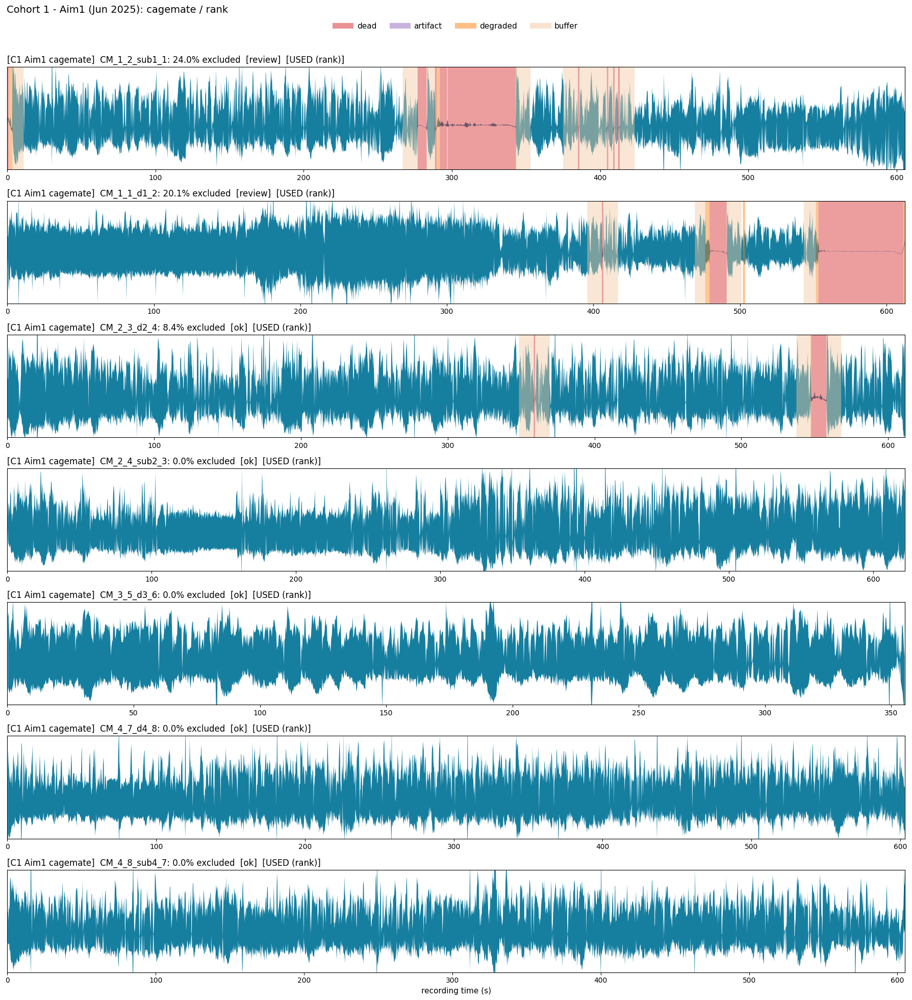

,recording,cohort,status,minutes,median_1s_range,excluded_pct,dead_s,artifact_s,degraded_s,buffer_s,flag,vs_group
0,CM_1_2_sub1_1,C1 Aim1 cagemate,USED (rank),10.09,2007.78,24.02,63.75,0.0,5.5,76.25,review,0.84
1,CM_1_1_d1_2,C1 Aim1 cagemate,USED (rank),10.21,1910.56,20.14,71.00,0.0,7.0,45.37,review,0.80
2,CM_2_3_d2_4,C1 Aim1 cagemate,USED (rank),10.19,2377.34,8.42,11.50,0.0,0.5,39.50,ok,1.00
3,CM_2_4_sub2_3,C1 Aim1 cagemate,USED (rank),10.37,2135.08,0.00,0.00,0.0,0.0,0.00,ok,0.90
4,CM_3_5_d3_6,C1 Aim1 cagemate,USED (rank),5.92,2901.75,0.00,0.00,0.0,0.0,0.00,ok,1.22
5,CM_4_7_d4_8,C1 Aim1 cagemate,USED (rank),10.05,2611.36,0.00,0.00,0.0,0.0,0.00,ok,1.10
6,CM_4_8_sub4_7,C1 Aim1 cagemate,USED (rank),10.08,2640.90,0.00,0.00,0.0,0.0,0.00,ok,1.11


In [ ]:
bad_by_cohort["aim1_cagemate"] = wb.bad_signal_report(recs, group="aim1_cagemate", row_height=2.8)
bad_by_cohort["aim1_cagemate"]


### 6.2 Cohort 1, Aim1 (Jun 2025): valence, BLRI baseline

7 recordings (there is no BLRI file for 3_5).

Cohort 1 - Aim1 (Jun 2025): valence, BLRI baseline: 7 recordings



Excluded stretches per recording (flag: >= 25% consider dropping, >= 10% review)

- BLRI_2_3                                      20.1% excluded (2.0 of 10.1 min)  [review]  [USED (valence)]
      10-38 s (dead+degraded); 47-78 s (dead+degraded); 170-191 s (dead); 400-422 s (dead); 515-536 s (dead)
- BLRI_2_4                                      20.0% excluded (2.0 of 10.1 min)  [review]  [USED (valence)]
      146-167 s (artifact); 220-243 s (dead); 286-308 s (dead); 320-353 s (dead+degraded); 451-472 s (artifact)
- BLRI_4_8                                       7.9% excluded (0.8 of 10.1 min)  [ok]  [USED (valence)]
      490-516 s (dead); 550-572 s (dead)
- BLRI_3_6                                       4.5% excluded (0.5 of 10.1 min)  [ok]  [USED (valence)]
      0-27 s (dead)
- BLRI_1_2                                       3.6% excluded (0.4 of 10.2 min)  [ok]  [USED (valence)]
      464-486 s (artifact)
- BLRI_4_7                                       3.5% excluded (0.4 of 10.1 

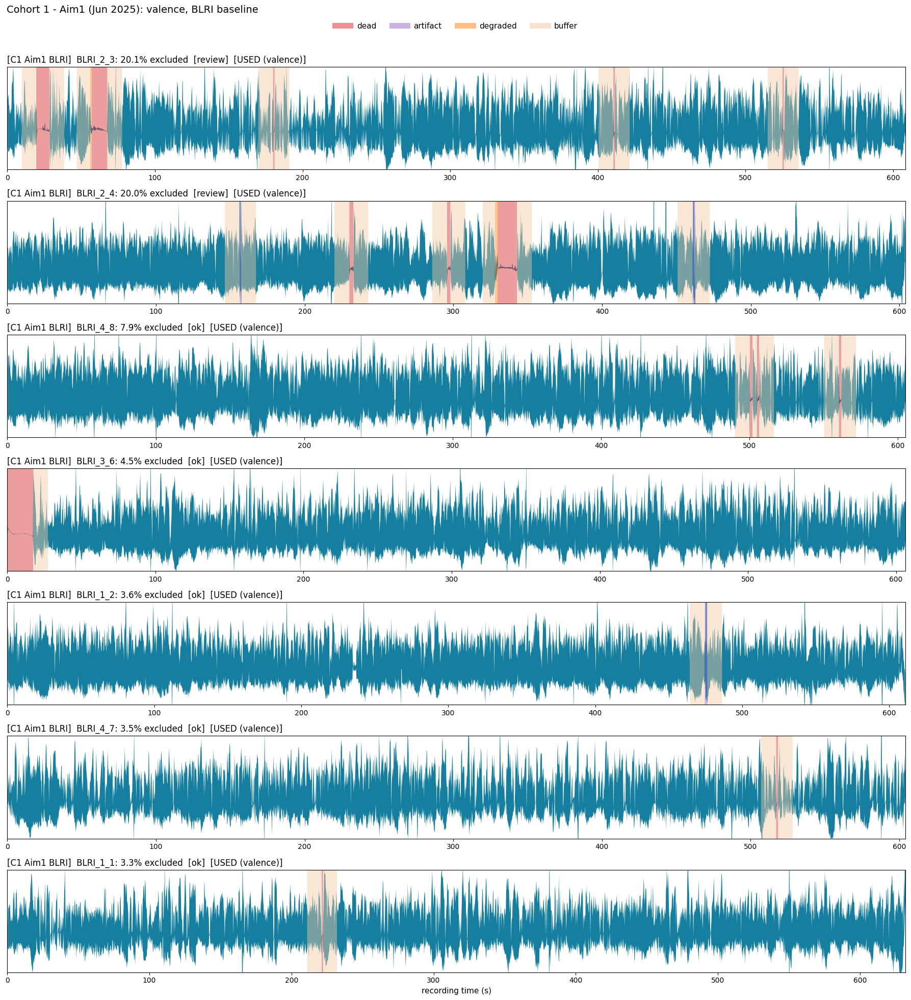

,recording,cohort,status,minutes,median_1s_range,excluded_pct,dead_s,artifact_s,degraded_s,buffer_s,flag,vs_group
0,BLRI_2_3,C1 Aim1 BLRI,USED (valence),10.14,2188.14,20.14,22.50,0.00,1.25,98.75,review,0.94
1,BLRI_2_4,C1 Aim1 BLRI,USED (valence),10.07,2836.09,19.99,18.00,2.75,2.00,98.00,review,1.22
2,BLRI_4_8,C1 Aim1 BLRI,USED (valence),10.08,2888.26,7.89,4.75,0.00,0.00,43.00,ok,1.25
3,BLRI_3_6,C1 Aim1 BLRI,USED (valence),10.10,2551.63,4.49,17.25,0.00,0.00,10.00,ok,1.10
4,BLRI_1_2,C1 Aim1 BLRI,USED (valence),10.18,2318.92,3.60,0.00,2.00,0.00,20.00,ok,1.00
5,BLRI_4_7,C1 Aim1 BLRI,USED (valence),10.07,2292.85,3.52,1.25,0.00,0.00,20.00,ok,0.99
6,BLRI_1_1,C1 Aim1 BLRI,USED (valence),10.53,2142.69,3.32,1.00,0.00,0.00,20.00,ok,0.92


In [ ]:
bad_by_cohort["aim1_blri"] = wb.bad_signal_report(recs, group="aim1_blri", row_height=2.8)
bad_by_cohort["aim1_blri"]


### 6.3 Cohort 1, Aim1 (Jun 2025): valence, RI1 positive

8 recordings.

Cohort 1 - Aim1 (Jun 2025): valence, RI1 positive: 8 recordings



Excluded stretches per recording (flag: >= 25% consider dropping, >= 10% review)

- RI1_2_3                                       18.7% excluded (1.9 of 10.0 min)  [review]  [USED (valence)]
      141-163 s (artifact); 218-266 s (dead+degraded); 361-382 s (dead); 383-404 s (dead)
- RI1_1_2                                       15.8% excluded (1.6 of 10.1 min)  [review]  [USED (valence)]
      125-150 s (dead+degraded); 171-214 s (dead+degraded); 223-251 s (dead+degraded)
- RI1_4_8                                       15.1% excluded (1.5 of 10.1 min)  [review]  [USED (valence)]
      56-86 s (dead+degraded); 416-450 s (dead); 476-502 s (dead+degraded)
- RI1_3_6                                       11.8% excluded (1.2 of 10.1 min)  [review]  [USED (valence)]
      191-212 s (dead); 344-372 s (dead+degraded); 407-428 s (artifact)
- RI1_1_1                                        7.7% excluded (0.8 of 10.4 min)  [ok]  [USED (valence)]
      355-376 s (dead); 541-564 s (degraded+dead); 574

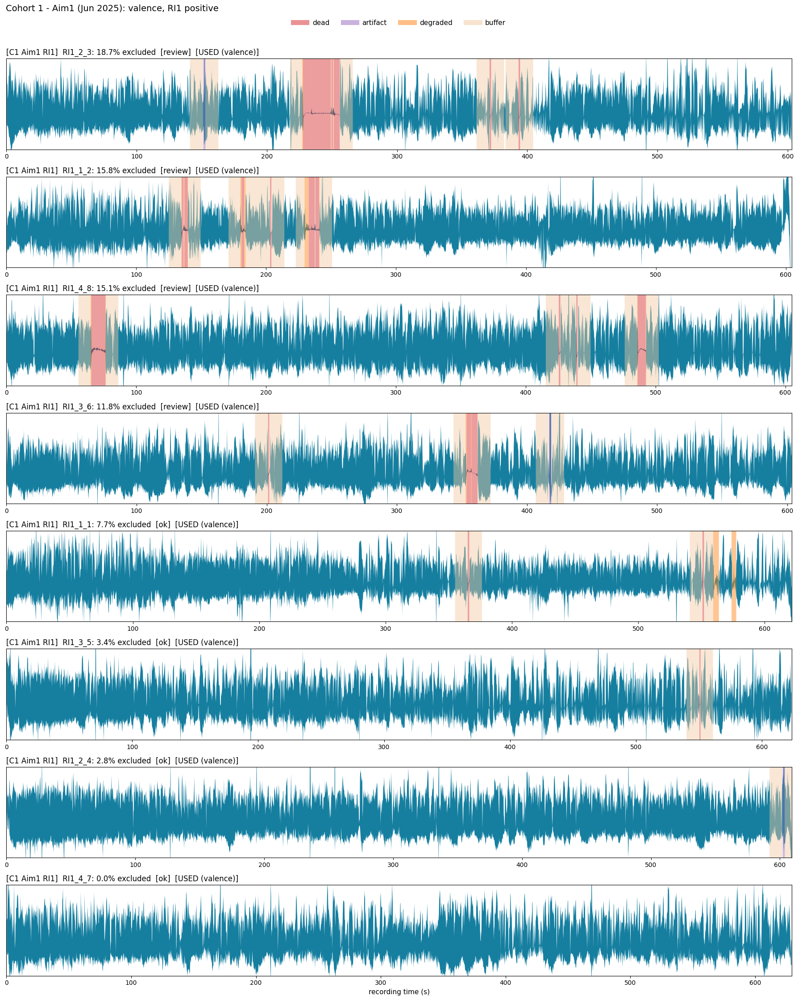

,recording,cohort,status,minutes,median_1s_range,excluded_pct,dead_s,artifact_s,degraded_s,buffer_s,flag,vs_group
0,RI1_2_3,C1 Aim1 RI1,USED (valence),10.05,2117.54,18.66,29.75,1.75,1.50,79.50,review,0.86
1,RI1_1_2,C1 Aim1 RI1,USED (valence),10.07,2357.99,15.80,14.75,0.00,7.50,73.25,review,0.96
2,RI1_4_8,C1 Aim1 RI1,USED (valence),10.08,2741.45,15.13,19.25,0.00,1.25,71.00,review,1.12
3,RI1_3_6,C1 Aim1 RI1,USED (valence),10.05,2368.80,11.81,9.25,1.75,1.00,59.25,review,0.96
4,RI1_1_1,C1 Aim1 RI1,USED (valence),10.35,2395.52,7.73,2.50,0.00,8.25,37.25,ok,0.97
5,RI1_3_5,C1 Aim1 RI1,USED (valence),10.40,2776.49,3.37,1.00,0.00,0.00,20.00,ok,1.13
6,RI1_2_4,C1 Aim1 RI1,USED (valence),10.15,2616.75,2.81,0.00,1.75,0.00,15.35,ok,1.06
7,RI1_4_7,C1 Aim1 RI1,USED (valence),10.49,2521.38,0.00,0.00,0.00,0.00,0.00,ok,1.03


In [ ]:
bad_by_cohort["aim1_ri1"] = wb.bad_signal_report(recs, group="aim1_ri1", row_height=2.8)
bad_by_cohort["aim1_ri1"]


### 6.4 Cohort 1, Aim1 (Jun 2025): valence, RI2 negative

8 recordings.

Cohort 1 - Aim1 (Jun 2025): valence, RI2 negative: 8 recordings



Excluded stretches per recording (flag: >= 25% consider dropping, >= 10% review)

- RI2_2_4                                       52.1% excluded (5.3 of 10.1 min)  [CONSIDER DROPPING]  [USED (valence)]
      195-334 s (degraded+dead+artifact); 345-390 s (dead+degraded); 399-486 s (dead+artifact+degraded); 493-515 s (artifact); 532-554 s (artifact)
- RI2_3_6                                       31.9% excluded (3.2 of 10.2 min)  [CONSIDER DROPPING]  [USED (valence)]
      0-34 s (artifact); 68-90 s (artifact); 108-136 s (degraded+artifact); 136-173 s (artifact); 250-273 s (artifact); 309-313 s (degraded); 324-328 s (degraded); 420-431 s (degraded); 434-452 s (degraded); 485-501 s (degraded)
- RI2_1_2                                       19.4% excluded (2.0 of 10.1 min)  [review]  [USED (valence)]
      134-159 s (dead+degraded); 284-347 s (dead+degraded); 576-604 s (dead+degraded)
- RI2_2_3                                       13.5% excluded (1.4 of 10.2 min)  [review]  [USED (valence

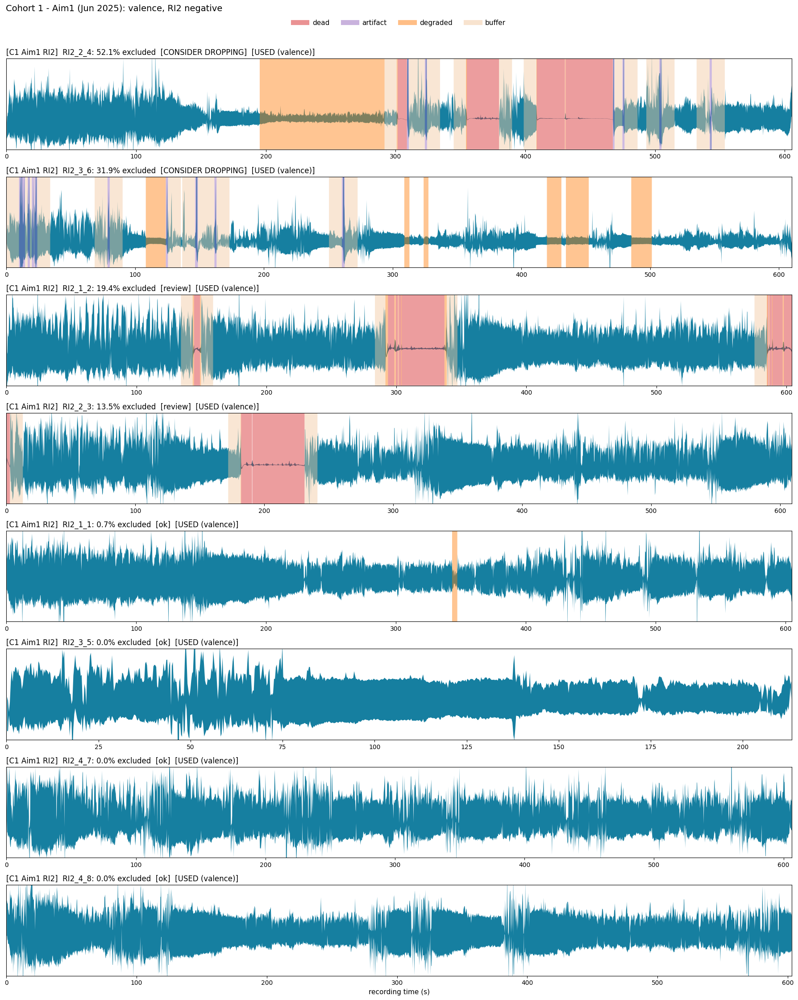

,recording,cohort,status,minutes,median_1s_range,excluded_pct,dead_s,artifact_s,degraded_s,buffer_s,flag,vs_group
0,RI2_2_4,C1 Aim1 RI2,USED (valence),10.09,1683.71,52.07,90.50,9.75,98.25,116.75,CONSIDER DROPPING,0.79
1,RI2_3_6,C1 Aim1 RI2,USED (valence),10.17,1296.56,31.93,0.00,20.25,68.25,106.25,CONSIDER DROPPING,0.61
2,RI2_1_2,C1 Aim1 RI2,USED (valence),10.07,1934.00,19.37,63.75,0.00,9.25,44.02,review,0.90
3,RI2_2_3,C1 Aim1 RI2,USED (valence),10.15,2147.81,13.46,51.75,0.00,0.75,29.50,review,1.00
4,RI2_1_1,C1 Aim1 RI2,USED (valence),10.08,2130.14,0.66,0.00,0.00,4.00,0.00,ok,1.00
5,RI2_3_5,C1 Aim1 RI2,USED (valence),3.56,2955.20,0.00,0.00,0.00,0.00,0.00,ok,1.38
6,RI2_4_7,C1 Aim1 RI2,USED (valence),10.11,2299.59,0.00,0.00,0.00,0.00,0.00,ok,1.08
7,RI2_4_8,C1 Aim1 RI2,USED (valence),10.05,2737.69,0.00,0.00,0.00,0.00,0.00,ok,1.28


In [ ]:
bad_by_cohort["aim1_ri2"] = wb.bad_signal_report(recs, group="aim1_ri2", row_height=2.8)
bad_by_cohort["aim1_ri2"]


### 6.5 Cohort 2, BLA pilot (Jan 2026): cagemate

24 recordings. Not used by the rank pipeline (no baseline). 8 are 25% or more excluded; none is low for the whole session.

Cohort 2 - BLA pilot (Jan 2026): cagemate: 24 recordings



Excluded stretches per recording (flag: >= 25% consider dropping, >= 10% review)

- 6_2_d_cm_6_3_s_20260107_154939                74.4% excluded (7.6 of 10.2 min)  [CONSIDER DROPPING]  [not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)]
      11-41 s (artifact); 42-210 s (dead+artifact+degraded); 222-300 s (dead+artifact+degraded); 309-331 s (artifact); 360-485 s (dead+degraded+artifact); 540-574 s (dead+degraded)
- 8_1_s_cm_8_2_d_20260107_152812                67.7% excluded (6.9 of 10.2 min)  [CONSIDER DROPPING]  [not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)]
      2-83 s (dead+degraded); 102-134 s (dead+degraded); 142-211 s (dead+degraded); 215-250 s (dead+degraded+artifact); 253-274 s (dead); 300-322 s (artifact); 330-416 s (dead+degraded); 445-467 s (dead); 471-493 s (dead); 584-609 s (dead+degraded)
- 3_1_i_cm_3_3_s_20260107_123230                35.7% excluded (3.6 of 10.1 min)  [CONSIDER DROPPING]  [not used (BLA cohort excluded: no baseline, EXCLUSIONS

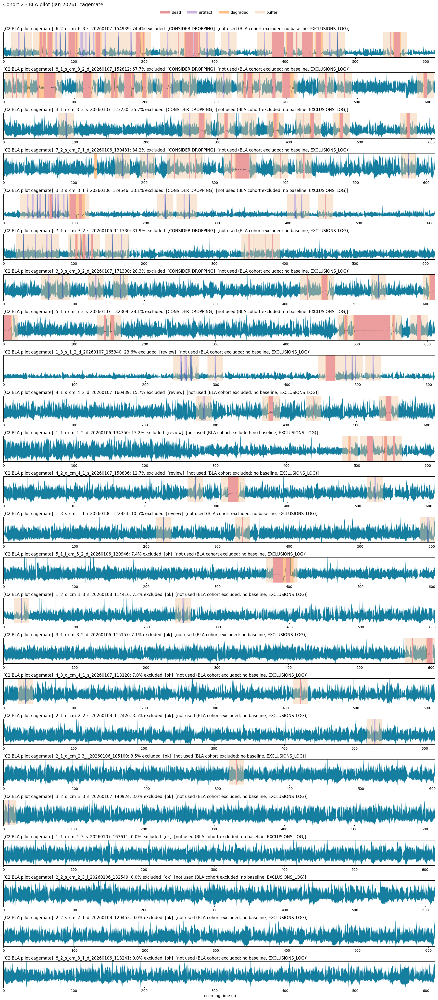

,recording,cohort,status,minutes,median_1s_range,excluded_pct,dead_s,artifact_s,degraded_s,buffer_s,flag,vs_group
0,6_2_d_cm_6_3_s_20260107_154939,C2 BLA pilot cagemate,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",10.22,590.05,74.38,114.25,36.50,32.25,273.00,CONSIDER DROPPING,0.60
1,8_1_s_cm_8_2_d_20260107_152812,C2 BLA pilot cagemate,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",10.17,968.28,67.66,101.75,3.75,34.50,272.75,CONSIDER DROPPING,0.98
2,3_1_i_cm_3_3_s_20260107_123230,C2 BLA pilot cagemate,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",10.09,535.70,35.69,31.50,3.00,10.00,171.50,CONSIDER DROPPING,0.54
3,7_2_s_cm_7_1_d_20260106_130431,C2 BLA pilot cagemate,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",10.21,937.42,34.21,28.25,5.25,6.00,170.00,CONSIDER DROPPING,0.95
4,3_3_s_cm_3_1_i_20260106_124546,C2 BLA pilot cagemate,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",10.11,1040.60,33.12,17.75,29.00,9.75,144.50,CONSIDER DROPPING,1.05
5,7_1_d_cm_7_2_s_20260106_111330,C2 BLA pilot cagemate,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",10.23,1254.91,31.91,14.50,12.25,2.50,166.50,CONSIDER DROPPING,1.27
6,3_3_s_cm_3_2_d_20260107_171330,C2 BLA pilot cagemate,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",10.22,974.04,28.33,17.00,9.75,3.50,143.40,CONSIDER DROPPING,0.99
7,5_1_i_cm_5_3_s_20260107_132309,C2 BLA pilot cagemate,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",10.18,885.97,28.12,78.50,0.00,9.00,84.25,CONSIDER DROPPING,0.90
8,1_3_s_1_2_d_20260107_165340,C2 BLA pilot cagemate,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",10.15,855.93,23.57,13.00,18.00,2.00,110.50,review,0.87
9,4_1_s_cm_4_2_d_20260107_160439,C2 BLA pilot cagemate,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",10.19,787.51,15.66,14.00,1.75,3.00,77.00,review,0.80


In [ ]:
bad_by_cohort["c2_cm"] = wb.bad_signal_report(wb.group_recordings("c2_cm"), group="c2_cm", row_height=1.7)
bad_by_cohort["c2_cm"]


### 6.6 Cohort 2, BLA pilot (Jan 2026): RI1 day 1

24 recordings.

- **Whole-session low:** 8 recordings (mice 2_3, 3_2, 5_1, 5_2, 5_3, 6_2, 6_3, 8_1).
- These recordings show noise only, with no breathing rhythm (raw range about 40 ADC counts against thousands normally). The same mice are normal in the cagemate sessions a few days earlier, so the sensor signal for those mice failed after the cagemate week.

Cohort 2 - BLA pilot (Jan 2026): RI1 day 1: 24 recordings



Excluded stretches per recording (flag: >= 25% consider dropping, >= 10% review)

- 3_2_RI1_f2_g_off_20260110_122606             100.0% excluded (4.2 of 4.2 min)  [CONSIDER DROPPING, WHOLE-SESSION LOW (0.05x group)]  [not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)]
      0-252 s (artifact+degraded+dead)
- 7_1_RI1_m1_k_on_20260111_160052               74.0% excluded (3.1 of 4.2 min)  [CONSIDER DROPPING]  [not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)]
      60-170 s (dead+degraded+artifact); 176-252 s (dead+degraded+artifact)
- 3_1_RI1_f1_b_on_20260111_154618               68.8% excluded (2.9 of 4.1 min)  [CONSIDER DROPPING]  [not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)]
      42-146 s (dead+degraded+artifact); 160-192 s (artifact+dead+degraded); 214-249 s (artifact+degraded+dead)
- 8_1_RI1_m2_m_on_20260110_144121               36.6% excluded (1.5 of 4.1 min)  [CONSIDER DROPPING, WHOLE-SESSION LOW (0.03x group)]  [not used (BLA cohort excluded:

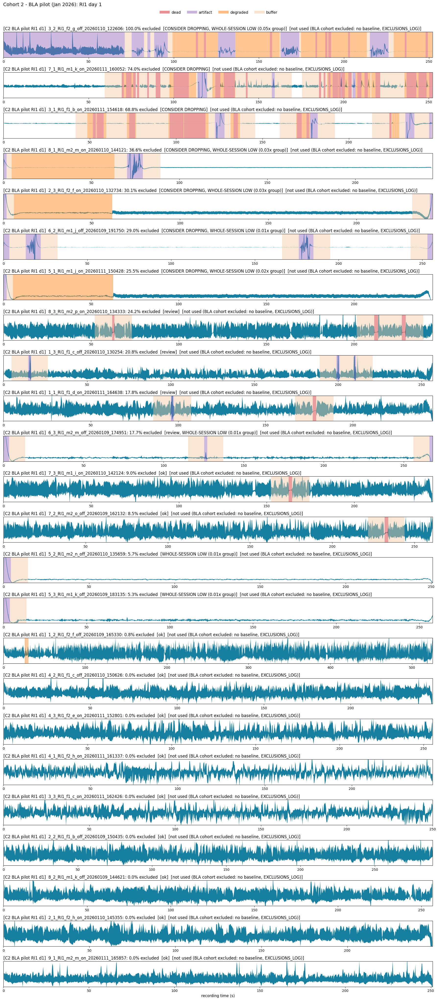

,recording,cohort,status,minutes,median_1s_range,excluded_pct,dead_s,artifact_s,degraded_s,buffer_s,flag,vs_group
0,3_2_RI1_f2_g_off_20260110_122606,C2 BLA pilot RI1 d1,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.20,27.13,100.00,11.00,120.50,103.25,17.41,"CONSIDER DROPPING, WHOLE-SESSION LOW (0.05x group)",0.05
1,7_1_RI1_m1_k_on_20260111_160052,C2 BLA pilot RI1 d1,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.21,1113.08,74.05,62.50,9.50,28.00,86.87,CONSIDER DROPPING,1.86
2,3_1_RI1_f1_b_on_20260111_154618,C2 BLA pilot RI1 d1,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.14,576.78,68.83,37.75,17.00,20.75,95.62,CONSIDER DROPPING,0.97
3,8_1_RI1_m2_m_on_20260110_144121,C2 BLA pilot RI1 d1,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.07,15.23,36.57,0.00,10.75,58.50,20.00,"CONSIDER DROPPING, WHOLE-SESSION LOW (0.03x group)",0.03
4,2_3_RI1_f2_f_on_20260110_132734,C2 BLA pilot RI1 d1,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.05,15.08,30.09,0.00,3.25,55.75,14.15,"CONSIDER DROPPING, WHOLE-SESSION LOW (0.03x group)",0.03
5,6_2_RI1_m1_j_off_20260109_191750,C2 BLA pilot RI1 d1,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.27,6.26,28.96,0.00,24.25,0.00,49.93,"CONSIDER DROPPING, WHOLE-SESSION LOW (0.01x group)",0.01
6,5_1_RI1_m1_j_on_20260111_150428,C2 BLA pilot RI1 d1,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.08,13.13,25.52,0.00,1.75,57.25,3.50,"CONSIDER DROPPING, WHOLE-SESSION LOW (0.02x group)",0.02
7,8_3_RI1_m2_p_on_20260110_134333,C2 BLA pilot RI1 d1,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.08,749.82,24.20,5.75,0.00,0.00,53.50,review,1.26
8,1_3_RI1_f1_c_off_20260110_130254,C2 BLA pilot RI1 d1,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.28,753.21,20.85,0.00,5.00,0.00,48.50,review,1.26
9,1_1_RI1_f1_d_on_20260111_164638,C2 BLA pilot RI1 d1,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.10,1097.66,17.80,2.00,1.75,0.00,40.00,review,1.84


In [ ]:
bad_by_cohort["c2_ri1_d1"] = wb.bad_signal_report(wb.group_recordings("c2_ri1_d1"), group="c2_ri1_d1", row_height=1.7)
bad_by_cohort["c2_ri1_d1"]


### 6.7 Cohort 2, BLA pilot (Jan 2026): RI1 day 2

24 recordings.

**Whole-session low:** 9 recordings (mice 1_2, 2_3, 4_1, 5_1, 5_2, 5_3, 6_2, 6_3, 8_1).

Cohort 2 - BLA pilot (Jan 2026): RI1 day 2: 24 recordings



Excluded stretches per recording (flag: >= 25% consider dropping, >= 10% review)

- 7_3_RI1_m2_n_off_20260111_134312              68.5% excluded (3.0 of 4.3 min)  [CONSIDER DROPPING]  [not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)]
      41-62 s (dead); 64-94 s (dead); 117-145 s (dead); 154-215 s (dead+degraded); 218-240 s (dead); 244-260 s (dead+degraded)
- 1_2_RI1_f1_b_on_20260110_192621               62.8% excluded (2.6 of 4.2 min)  [CONSIDER DROPPING, WHOLE-SESSION LOW (0.03x group)]  [not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)]
      0-148 s (artifact+degraded); 242-253 s (degraded+artifact)
- 5_1_RI1_m2_m_off_20260110_174649              42.2% excluded (1.9 of 4.5 min)  [CONSIDER DROPPING, WHOLE-SESSION LOW (0.01x group)]  [not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)]
      0-50 s (artifact); 51-114 s (artifact)
- 3_2_RI1_f2_e_on_20260112_130721               36.8% excluded (1.5 of 4.1 min)  [CONSIDER DROPPING]  [not used (BLA cohort

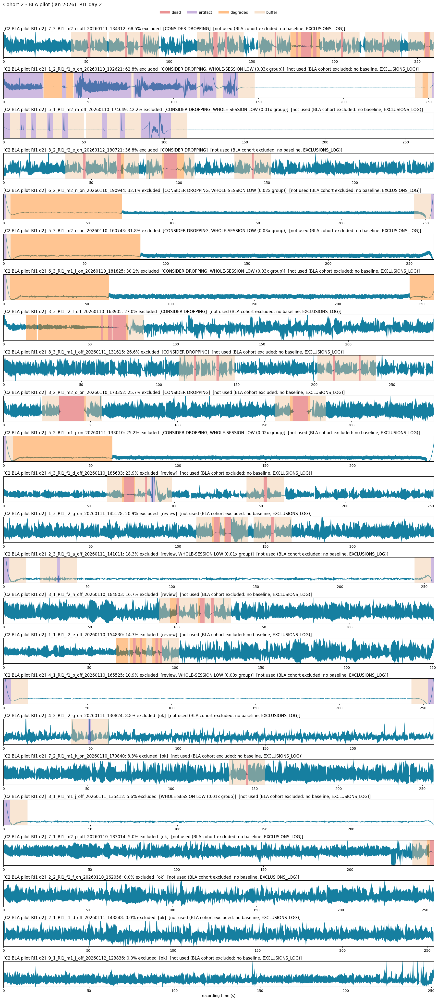

,recording,cohort,status,minutes,median_1s_range,excluded_pct,dead_s,artifact_s,degraded_s,buffer_s,flag,vs_group
0,7_3_RI1_m2_n_off_20260111_134312,C2 BLA pilot RI1 d2,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.33,1430.63,68.55,23.50,0.00,9.75,144.92,CONSIDER DROPPING,2.40
1,1_2_RI1_f1_b_on_20260110_192621,C2 BLA pilot RI1 d2,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.22,18.22,62.78,0.00,116.50,18.00,24.45,"CONSIDER DROPPING, WHOLE-SESSION LOW (0.03x group)",0.03
2,5_1_RI1_m2_m_off_20260110_174649,C2 BLA pilot RI1 d2,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.46,3.60,42.23,0.00,43.25,0.00,69.75,"CONSIDER DROPPING, WHOLE-SESSION LOW (0.01x group)",0.01
3,3_2_RI1_f2_e_on_20260112_130721,C2 BLA pilot RI1 d2,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.09,1061.04,36.81,12.25,0.00,6.50,71.50,CONSIDER DROPPING,1.78
4,6_2_RI1_m2_n_on_20260110_190944,C2 BLA pilot RI1 d2,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.25,14.72,32.14,0.00,3.00,66.00,12.93,"CONSIDER DROPPING, WHOLE-SESSION LOW (0.02x group)",0.02
5,5_3_RI1_m2_o_on_20260110_160743,C2 BLA pilot RI1 d2,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.42,15.25,31.78,0.00,1.75,80.00,2.50,"CONSIDER DROPPING, WHOLE-SESSION LOW (0.03x group)",0.03
6,6_3_RI1_m1_i_on_20260110_181825,C2 BLA pilot RI1 d2,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.29,15.07,30.09,0.00,1.50,73.50,2.50,"CONSIDER DROPPING, WHOLE-SESSION LOW (0.03x group)",0.03
7,3_3_RI1_f2_f_off_20260110_163905,C2 BLA pilot RI1 d2,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.16,351.18,27.03,11.00,0.00,47.50,9.00,CONSIDER DROPPING,0.59
8,8_3_RI1_m1_l_off_20260111_131615,C2 BLA pilot RI1 d2,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.62,1304.61,26.63,5.00,0.00,0.00,68.75,CONSIDER DROPPING,2.19
9,8_2_RI1_m2_o_on_20260110_173352,C2 BLA pilot RI1 d2,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.13,735.40,25.65,23.50,0.00,3.50,36.50,CONSIDER DROPPING,1.23


In [ ]:
bad_by_cohort["c2_ri1_d2"] = wb.bad_signal_report(wb.group_recordings("c2_ri1_d2"), group="c2_ri1_d2", row_height=1.7)
bad_by_cohort["c2_ri1_d2"]


### 6.8 Cohort 2, BLA pilot (Jan 2026): RI2 post day 1

23 recordings.

**Whole-session low:** 5 recordings (mice 2_3, 5_1, 5_2, 5_3, 6_3).

Cohort 2 - BLA pilot (Jan 2026): RI2 post day 1: 23 recordings



Excluded stretches per recording (flag: >= 25% consider dropping, >= 10% review)

- 8_1_RI2_m1_i_off_20260119_162623              96.7% excluded (4.1 of 4.3 min)  [CONSIDER DROPPING]  [not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)]
      0-145 s (dead+degraded+artifact); 154-257 s (dead+degraded+artifact)
- 7_2_RI2_m1_i_on_20260119_140337               91.0% excluded (4.0 of 4.4 min)  [CONSIDER DROPPING]  [not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)]
      0-2 s (degraded); 6-28 s (artifact); 38-76 s (artifact+degraded); 80-102 s (artifact); 107-157 s (artifact); 159-267 s (artifact)
- 5_1_RI2_m2_p_off_20260119_143035              90.8% excluded (3.9 of 4.3 min)  [CONSIDER DROPPING, WHOLE-SESSION LOW (0.00x group)]  [not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)]
      0-25 s (artifact); 34-120 s (artifact); 130-170 s (degraded+artifact); 176-259 s (artifact)
- 3_2_RI2_f1_b_on_20260119_181446               69.8% excluded (2.9 of 4.1 min)  [CO

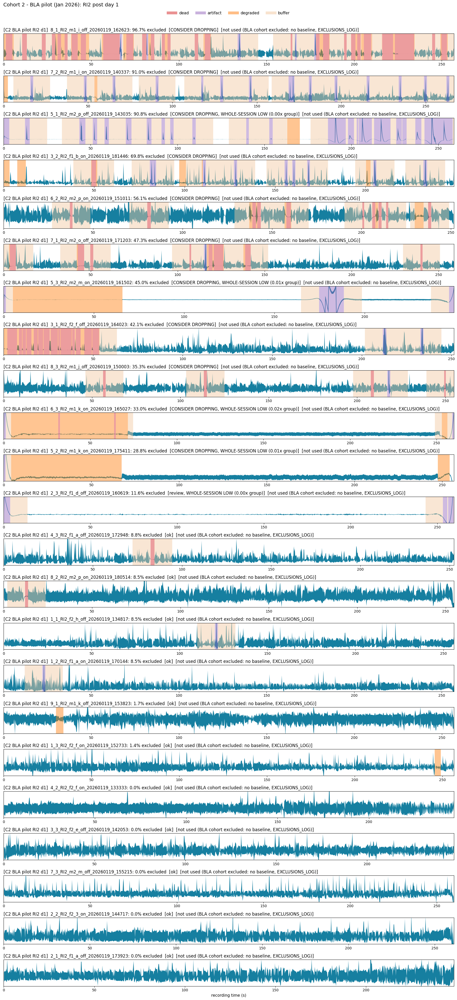

,recording,cohort,status,minutes,median_1s_range,excluded_pct,dead_s,artifact_s,degraded_s,buffer_s,flag,vs_group
0,8_1_RI2_m1_i_off_20260119_162623,C2 BLA pilot RI2 d1,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.28,3857.22,96.69,86.75,6.00,23.50,132.26,CONSIDER DROPPING,2.40
1,7_2_RI2_m1_i_on_20260119_140337,C2 BLA pilot RI2 d1,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.45,848.17,91.00,0.00,25.75,4.25,212.78,CONSIDER DROPPING,0.53
2,5_1_RI2_m2_p_off_20260119_143035,C2 BLA pilot RI2 d1,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.32,5.66,90.83,0.00,87.25,7.25,140.77,"CONSIDER DROPPING, WHOLE-SESSION LOW (0.00x group)",0.00
3,3_2_RI2_f1_b_on_20260119_181446,C2 BLA pilot RI2 d1,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.15,809.97,69.81,2.50,15.75,15.75,139.75,CONSIDER DROPPING,0.50
4,6_2_RI2_m2_p_on_20260119_151011,C2 BLA pilot RI2 d1,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.20,1860.07,56.11,17.50,0.00,10.25,113.50,CONSIDER DROPPING,1.16
5,7_1_RI2_m2_o_off_20260119_171203,C2 BLA pilot RI2 d1,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.31,712.45,47.33,22.25,1.75,4.00,94.50,CONSIDER DROPPING,0.44
6,5_3_RI2_m2_m_on_20260119_161502,C2 BLA pilot RI2 d1,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.16,16.13,45.00,0.00,17.75,60.75,33.78,"CONSIDER DROPPING, WHOLE-SESSION LOW (0.01x group)",0.01
7,3_1_RI2_f2_f_off_20260119_164023,C2 BLA pilot RI2 d1,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.19,1654.98,42.14,44.00,3.75,9.50,48.75,CONSIDER DROPPING,1.03
8,8_3_RI2_m1_j_off_20260119_150003,C2 BLA pilot RI2 d1,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.25,1604.01,35.26,6.00,1.75,0.00,82.11,CONSIDER DROPPING,1.00
9,6_3_RI2_m1_k_on_20260119_165027,C2 BLA pilot RI2 d1,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.33,39.34,33.00,2.00,2.25,68.75,12.81,"CONSIDER DROPPING, WHOLE-SESSION LOW (0.02x group)",0.02


In [ ]:
bad_by_cohort["c2_ri2_d1"] = wb.bad_signal_report(wb.group_recordings("c2_ri2_d1"), group="c2_ri2_d1", row_height=1.7)
bad_by_cohort["c2_ri2_d1"]


### 6.9 Cohort 2, BLA pilot (Jan 2026): RI2 post day 2

23 recordings.

- **Whole-session low:** 6 recordings (mice 2_3, 5_1, 5_2, 5_3, 6_2, 6_3).
- Mice 2_3, 5_1, 5_2, 5_3 and 6_3 are low in **all four** RI sessions.

Cohort 2 - BLA pilot (Jan 2026): RI2 post day 2: 23 recordings



Excluded stretches per recording (flag: >= 25% consider dropping, >= 10% review)

- 6_2_RI2_m1_I_off_20260120_142228             100.0% excluded (4.1 of 4.1 min)  [CONSIDER DROPPING, WHOLE-SESSION LOW (0.03x group)]  [not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)]
      0-248 s (artifact+degraded+dead)
- 5_1_RI2_m1_j_on_20260120_172322               76.7% excluded (3.5 of 4.6 min)  [CONSIDER DROPPING, WHOLE-SESSION LOW (0.01x group)]  [not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)]
      0-96 s (degraded+artifact); 116-168 s (artifact); 183-240 s (artifact); 269-276 s (degraded)
- 7_1_RI2_m1_j_on_20260120_122806               56.6% excluded (2.5 of 4.4 min)  [CONSIDER DROPPING]  [not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)]
      4-26 s (artifact); 62-83 s (artifact); 84-131 s (artifact); 137-173 s (artifact); 181-183 s (degraded); 194-216 s (degraded+artifact)
- 7_3_RI2_m1_j_on_20260120_153051               55.3% excluded (2.3 of 4.1 min)  [

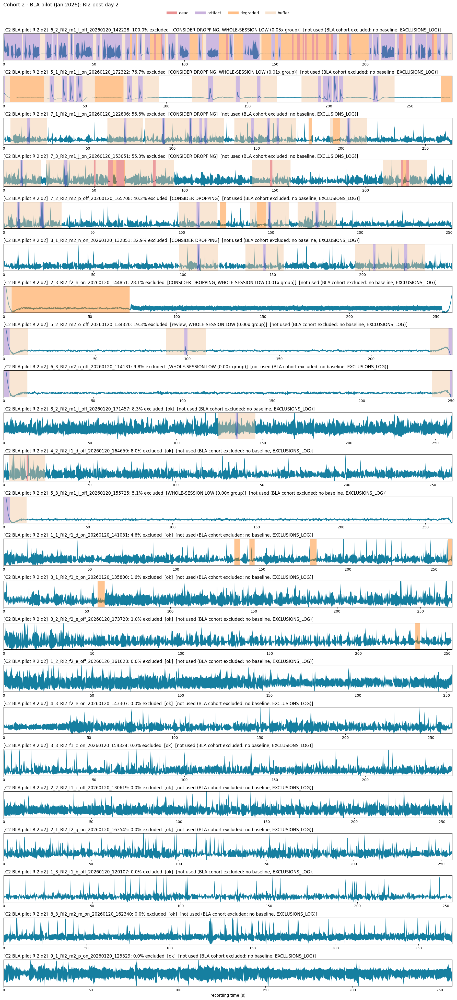

,recording,cohort,status,minutes,median_1s_range,excluded_pct,dead_s,artifact_s,degraded_s,buffer_s,flag,vs_group
0,6_2_RI2_m1_I_off_20260120_142228,C2 BLA pilot RI2 d2,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.13,19.77,100.00,18.0,137.25,64.00,28.68,"CONSIDER DROPPING, WHOLE-SESSION LOW (0.03x group)",0.03
1,5_1_RI2_m1_j_on_20260120_172322,C2 BLA pilot RI2 d2,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.60,7.91,76.74,0.0,43.75,45.25,122.75,"CONSIDER DROPPING, WHOLE-SESSION LOW (0.01x group)",0.01
2,7_1_RI2_m1_j_on_20260120_122806,C2 BLA pilot RI2 d2,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.43,608.35,56.62,0.0,17.50,6.00,127.00,CONSIDER DROPPING,1.00
3,7_3_RI2_m1_j_on_20260120_153051,C2 BLA pilot RI2 d2,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.13,687.07,55.29,13.5,3.25,4.00,116.25,CONSIDER DROPPING,1.13
4,7_2_RI2_m2_p_off_20260120_165708,C2 BLA pilot RI2 d2,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.20,585.99,40.22,0.0,9.25,8.50,83.50,CONSIDER DROPPING,0.96
5,8_1_RI2_m2_n_on_20260120_132851,C2 BLA pilot RI2 d2,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.17,780.85,32.91,0.0,6.25,0.00,76.00,CONSIDER DROPPING,1.28
6,2_3_RI2_f2_h_on_20260120_144851,C2 BLA pilot RI2 d2,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.32,7.65,28.06,0.0,1.00,68.25,3.50,"CONSIDER DROPPING, WHOLE-SESSION LOW (0.01x group)",0.01
7,5_2_RI2_m2_o_off_20260120_134320,C2 BLA pilot RI2 d2,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.07,2.72,19.26,0.0,6.75,0.00,40.23,"review, WHOLE-SESSION LOW (0.00x group)",0.00
8,6_3_RI2_m2_n_off_20260120_114131,C2 BLA pilot RI2 d2,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.18,2.92,9.80,0.0,4.50,0.00,20.05,WHOLE-SESSION LOW (0.00x group),0.00
9,8_2_RI2_m1_l_off_20260120_171457,C2 BLA pilot RI2 d2,"not used (BLA cohort excluded: no baseline, EXCLUSIONS_LOG)",4.33,499.37,8.28,0.0,1.50,0.00,20.00,ok,0.82


In [ ]:
bad_by_cohort["c2_ri2_d2"] = wb.bad_signal_report(wb.group_recordings("c2_ri2_d2"), group="c2_ri2_d2", row_height=1.7)
bad_by_cohort["c2_ri2_d2"]


### 6.10 Cohort 3, BLA cohort 2 (Jul 2026): cagemate

11 recordings, including the 3 sessions in Section 1.

Cohort 3 - BLA cohort 2 (Jul 2026): cagemate: 11 recordings



Excluded stretches per recording (flag: >= 25% consider dropping, >= 10% review)

- 10_2_d_CM_10_1_s_20260729_114455              48.1% excluded (5.0 of 10.4 min)  [CONSIDER DROPPING]  [not used yet (new cohort; Sequoia's QC)]
      0-11 s (artifact); 16-38 s (artifact); 161-183 s (artifact); 242-264 s (artifact); 318-322 s (degraded); 324-328 s (degraded); 333-341 s (degraded); 344-368 s (degraded); 370-373 s (degraded); 374-379 s (degraded); 382-388 s (degraded); 391-423 s (degraded); 424-551 s (degraded+dead); 596-598 s (degraded); 606-612 s (degraded); 619-622 s (degraded)
- 11_2_s_CM_11_4_d_20260729_172306              38.4% excluded (4.6 of 11.9 min)  [CONSIDER DROPPING]  [not used yet (new cohort; Sequoia's QC)]
      0-12 s (artifact); 58-95 s (artifact); 126-148 s (degraded+dead); 182-203 s (degraded+dead); 213-246 s (dead+artifact+degraded); 269-290 s (dead); 322-342 s (dead); 472-519 s (dead+degraded); 524-561 s (artifact); 656-678 s (artifact)
- 11_3_s_CM_11_4_d_20260729_12

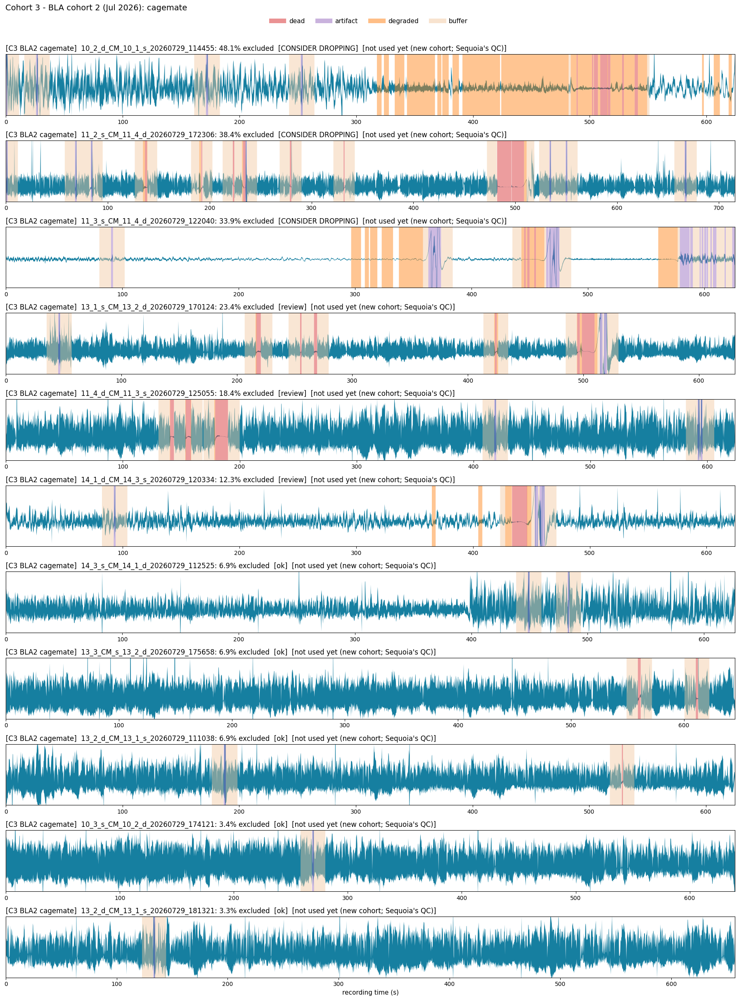

,recording,cohort,status,minutes,median_1s_range,excluded_pct,dead_s,artifact_s,degraded_s,buffer_s,flag,vs_group
0,10_2_d_CM_10_1_s_20260729_114455,C3 BLA2 cagemate,not used yet (new cohort; Sequoia's QC),10.41,324.44,48.13,18.25,6.75,201.75,73.75,CONSIDER DROPPING,0.33
1,11_2_s_CM_11_4_d_20260729_172306,C3 BLA2 cagemate,not used yet (new cohort; Sequoia's QC),11.93,1117.23,38.36,35.75,12.00,8.00,218.75,CONSIDER DROPPING,1.14
2,11_3_s_CM_11_4_d_20260729_122040,C3 BLA2 cagemate,not used yet (new cohort; Sequoia's QC),10.43,341.80,33.91,5.00,47.75,80.25,79.32,CONSIDER DROPPING,0.35
3,13_1_s_CM_13_2_d_20260729_170124,C3 BLA2 cagemate,not used yet (new cohort; Sequoia's QC),10.52,1060.64,23.41,22.75,7.00,7.25,110.75,review,1.09
4,11_4_d_CM_11_3_s_20260729_125055,C3 BLA2 cagemate,not used yet (new cohort; Sequoia's QC),10.39,975.92,18.40,18.75,5.25,1.75,89.00,review,1.00
5,14_1_d_CM_14_3_s_20260729_120334,C3 BLA2 cagemate,not used yet (new cohort; Sequoia's QC),10.40,510.77,12.29,13.00,9.25,16.25,38.25,review,0.52
6,14_3_s_CM_14_1_d_20260729_112525,C3 BLA2 cagemate,not used yet (new cohort; Sequoia's QC),10.44,514.90,6.90,0.00,3.25,0.00,40.00,ok,0.53
7,13_3_CM_s_13_2_d_20260729_175658,C3 BLA2 cagemate,not used yet (new cohort; Sequoia's QC),10.75,1273.41,6.90,4.50,0.00,0.00,40.00,ok,1.30
8,13_2_d_CM_13_1_s_20260729_111038,C3 BLA2 cagemate,not used yet (new cohort; Sequoia's QC),10.41,820.34,6.88,1.00,2.00,0.00,40.00,ok,0.84
9,10_3_s_CM_10_2_d_20260729_174121,C3 BLA2 cagemate,not used yet (new cohort; Sequoia's QC),10.66,1231.81,3.40,0.00,1.75,0.00,20.00,ok,1.26


In [ ]:
bad_by_cohort["c3_cm"] = wb.bad_signal_report(wb.group_recordings("c3_cm"), group="c3_cm", row_height=2.2)
bad_by_cohort["c3_cm"]
